# Continual learning in weight space: three rounds of agent memory into an LLM

**A guided notebook on learning again and again without losing what came before**

The first notebook did one consolidation: an agent's memory traces became training rows, one LoRA run moved them into the weights of **Qwen3.5-27B**, and a held-out test measured the change. This notebook repeats that cycle **three times**, as the agent's knowledge grows and some of it changes, and measures what each round **keeps** as carefully as what it **adds**.

## What you will learn

- Why a loop is harder than a single fine-tune: **forgetting**, **changed facts**, and the question of **what to replay**
- What **catastrophic forgetting** is, why shared weights cause it, and how the brain's two learning systems avoid it
- How a changed fact travels from a `memory_update` in a trace to a superseded unit in the store, to training rows, to a test that fails if the old value comes back
- How to build each round's training set, with and without **replay**, and why the replay pool has to be filtered
- How to read a **retention grid**, and what **average accuracy** and **backward transfer** measure
- What every setting and function in the experiment does, before you run the cell that uses it

## How the notebook is organised

| Part | What it covers | Runs code? |
|---|---|---|
| 1 | From one run to a loop: what changes | No |
| 2 | Why networks forget, and how the brain avoids it | Yes (a small NumPy demonstration) |
| 3 | The use case over time: three rounds of Calderwood | No |
| 4 | Setup: install, settings and data | Yes |
| 5 | Follow one changed fact through the pipeline | Yes |
| 6 | The model and the adapter | Yes |
| 7 | The evaluation harness, extended for a loop | Yes |
| 8 | Building each round's training set | Yes |
| 9 | The training round and the two arms | Yes |
| 10 | Run the experiment | Yes (most of the runtime) |
| 11 | The retention grid and the metrics | Yes |
| 12 | The changed facts, and what each round lost | Yes |
| 13 | Reading the results and where to go next | Yes |
| Reference | Common errors, glossary, further reading | No |

Every part opens with the idea, then explains each setting **before** the cell that uses it. Where you see **Predict first**, work out the answer before you run the next cell; the cell then checks you.

## What you need

- **An A100 80GB runtime** (Colab Pro: Runtime → Change runtime type → A100, High-RAM). The model is about 54GB in 16-bit. Colab's A100 option can hand you a 40GB card instead, and an L4 has about 22GB; Part 6 checks which one you got and tells you which loading setting to change so the model still fits. A T4 is too small.
- **`calderwood_data_v2.zip`**, uploaded to the Colab root folder (not into `sample_data`). This is the dataset repaired after the first run, with a `rounds/` folder inside.
- **Roughly 60 to 80 minutes** for the full experiment: six training rounds (three per arm) and about 230 scored questions per arm. Setting `QUICK = True` in Part 4 scores 12 questions per round and takes about half that.

It helps to have worked through the first notebook, `Qwen3_5_27B_Calderwood_memory_traces_guided.ipynb`, which explains weights, LoRA, chat templates and the training settings from the ground up. This notebook recaps each of them in a few lines where they appear and spends its time on what a loop adds.

The first notebook has a reference run to compare with. This one produces its own numbers: nothing below quotes a result in advance, and the reading guide in Part 13 tells you what each pattern would mean.

---
# Part 1: From one run to a loop

## Where the first notebook stopped

**Continual learning** is accumulating information and experience repeatedly, over time, so that each round does better than the last **and keeps what came before**. The first notebook covered the first half of that sentence, once: it took what the Calderwood support agent had learned in September and October 2026 and trained it into the weights.

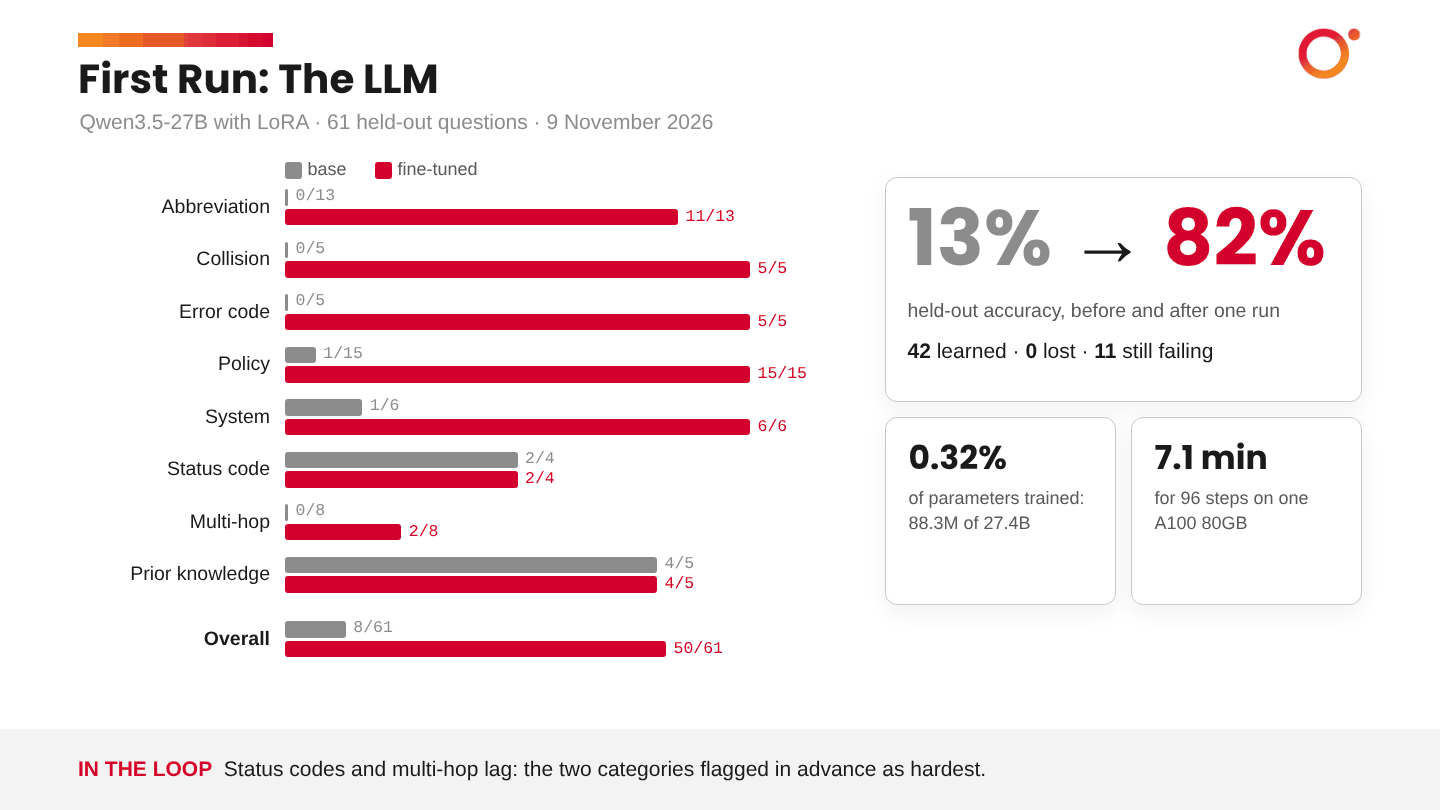

*Figure 1. The first notebook's result on the first-run dataset: 13% to 82% on 61 held-out questions after one LoRA run. That run is round one of the loop this notebook builds.*

Agent memory is the foundation for that run. Every training row started life as a memory the agent kept in its store. The store sits in **token space**: text outside the model, which the model reads. Fine-tuning moved a stable part of it into **weight space**: the model's own parameters.

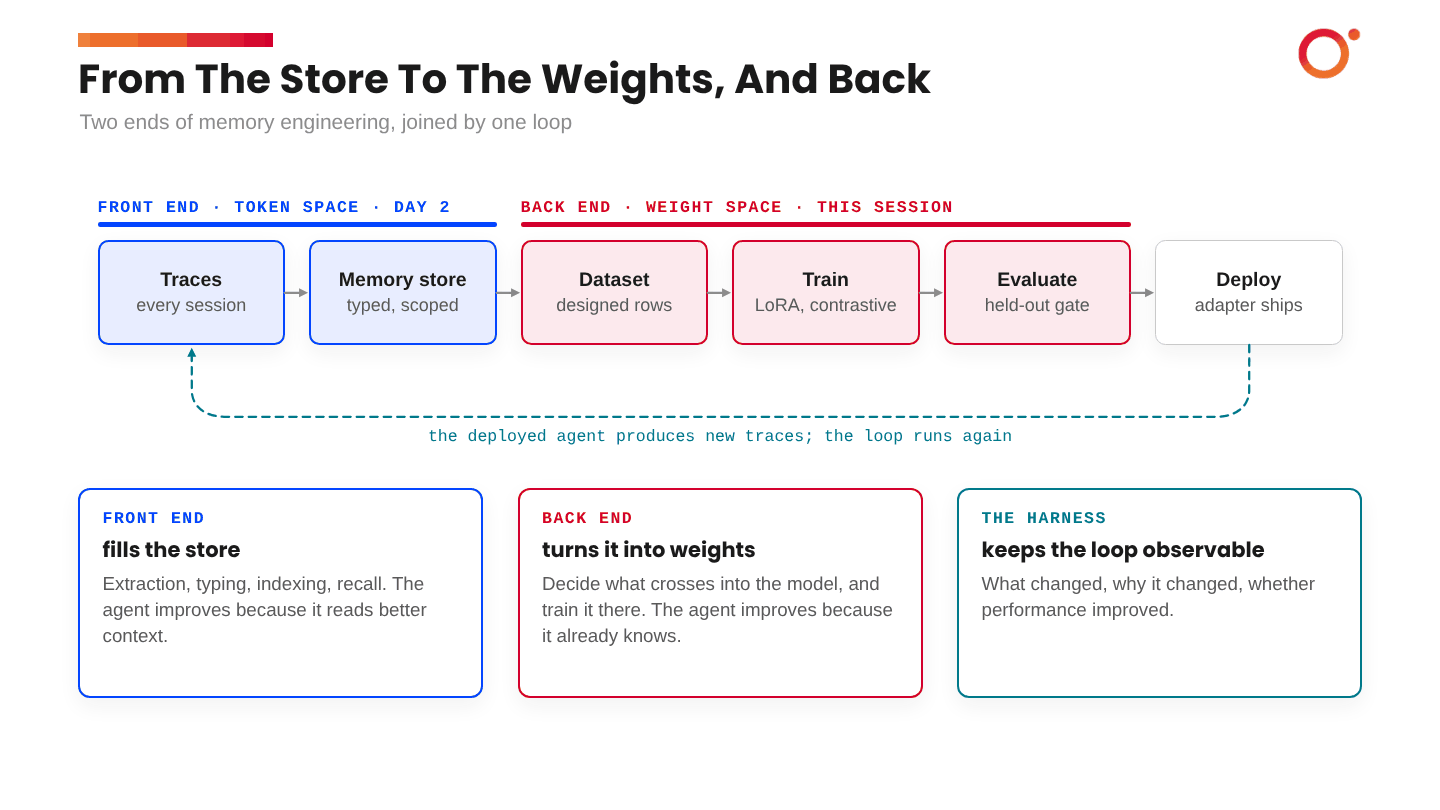

*Figure 2. Two ends of memory engineering, joined by one loop. The deployed agent keeps producing traces, so the loop on the right has to run again.*

## What a loop adds

The agent does not stop working after the first fine-tune. New systems launch, limits change, and the store fills with new memory units. So the round has to repeat.

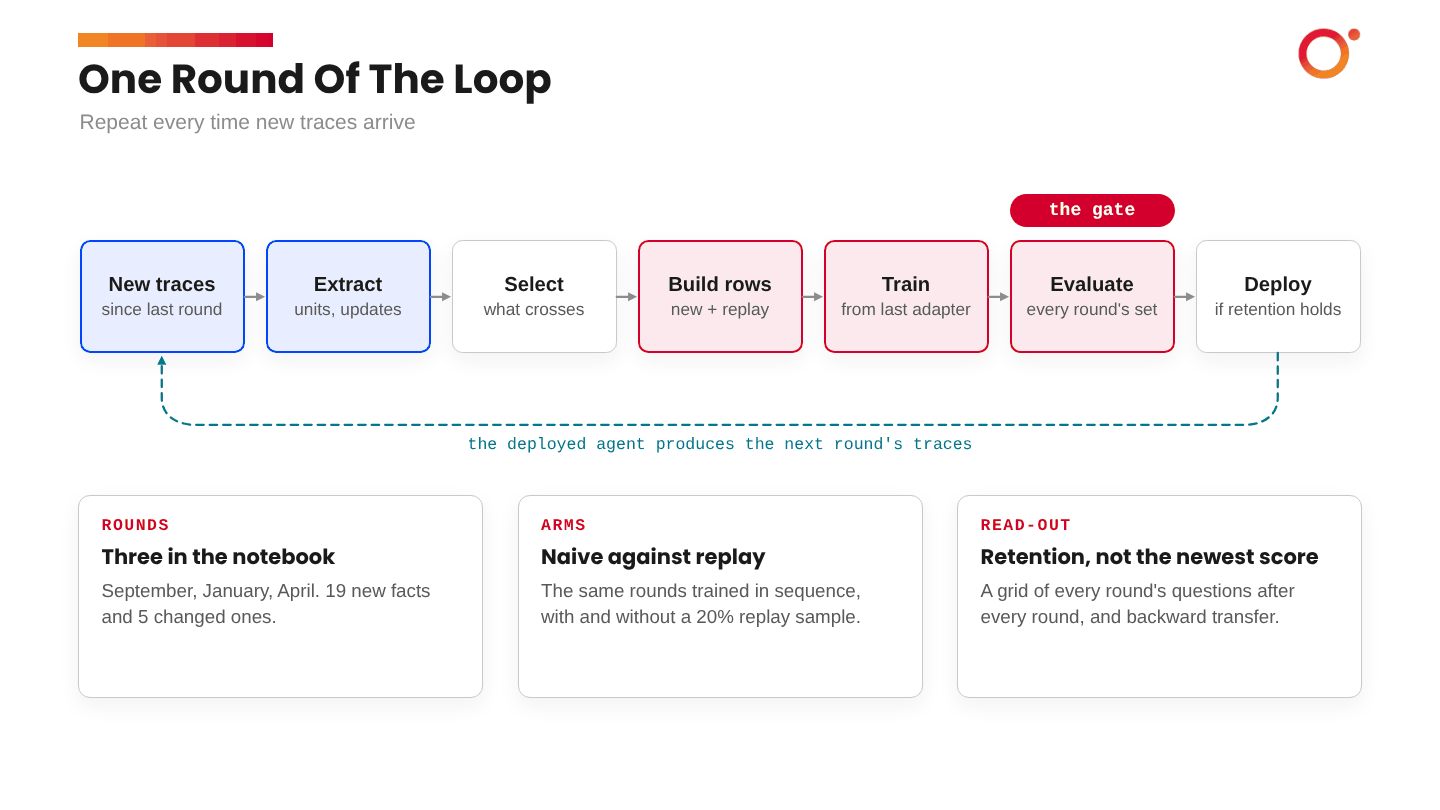

*Figure 3. One round of the loop. Each round starts from the previous round's adapter, and ships only if the evaluation shows that earlier knowledge held.*

A single fine-tune only has to get new facts in. A loop has three extra problems, and this notebook is built around them.

1. **Forgetting.** Training on round 2 moves the same weights that hold round 1. To see the damage as a number, round 1's held-out questions are re-tested after every later round.
2. **Changed facts.** Some round-1 facts stop being true. The memory store can mark the old unit as superseded and keep it for the record. The weights cannot delete anything; the old value can only be overwritten by training. So the test for a changed fact passes only if the answer gives the **new** value and **not** the old one.
3. **What to replay.** Mixing a sample of earlier rows into each round is the standard defence against forgetting. But replaying a row whose fact has since changed would teach the old value straight back in, so the replay pool has to leave those rows out.

## The experiment: two arms

To show what replay is worth, the notebook trains the same three rounds twice.

- **Arm A, naive sequential.** Each round trains only on that round's rows. This is the forgetting demonstration.
- **Arm B, replay.** Each round trains on its own rows plus a 20% sample of earlier rounds' rows, minus any row tied to a fact that has since changed.

An **arm** is one version of an experiment. The two arms use the same model, the same adapter settings, the same data and the same test. Only the replay rule differs, so any difference in the results can be put down to replay.

## The measurements

After training round *k*, every round *j* up to *k* is re-tested. That gives a **retention grid**: rows are "after round k", columns are "round j's questions". Three numbers summarise it:

- **Average accuracy (ACC):** the score across all rounds' questions after the final round.
- **Backward transfer (BWT):** for each earlier round, the score after the final round minus the score right after that round was learned. Negative means forgetting.
- **Changed-fact accuracy:** on the five changed facts, does the model give the new value and not the old one?

Part 11 defines each of these exactly, with a worked example.

---
# Part 2: Why networks forget, and how the brain avoids it

## One set of weights holds everything

A neural network does not keep each fact in its own slot. Everything it knows is spread across the same shared weights. A training step for a new fact nudges many of those weights, and some of them were holding up something the model already knew. Nothing raises an error when that happens. The old answer just quietly gets worse.

This is **catastrophic forgetting**. The name goes back to a 1989 study by McCloskey and Cohen, in which a small network that had learned the ones addition facts lost them after a single pass over the twos.

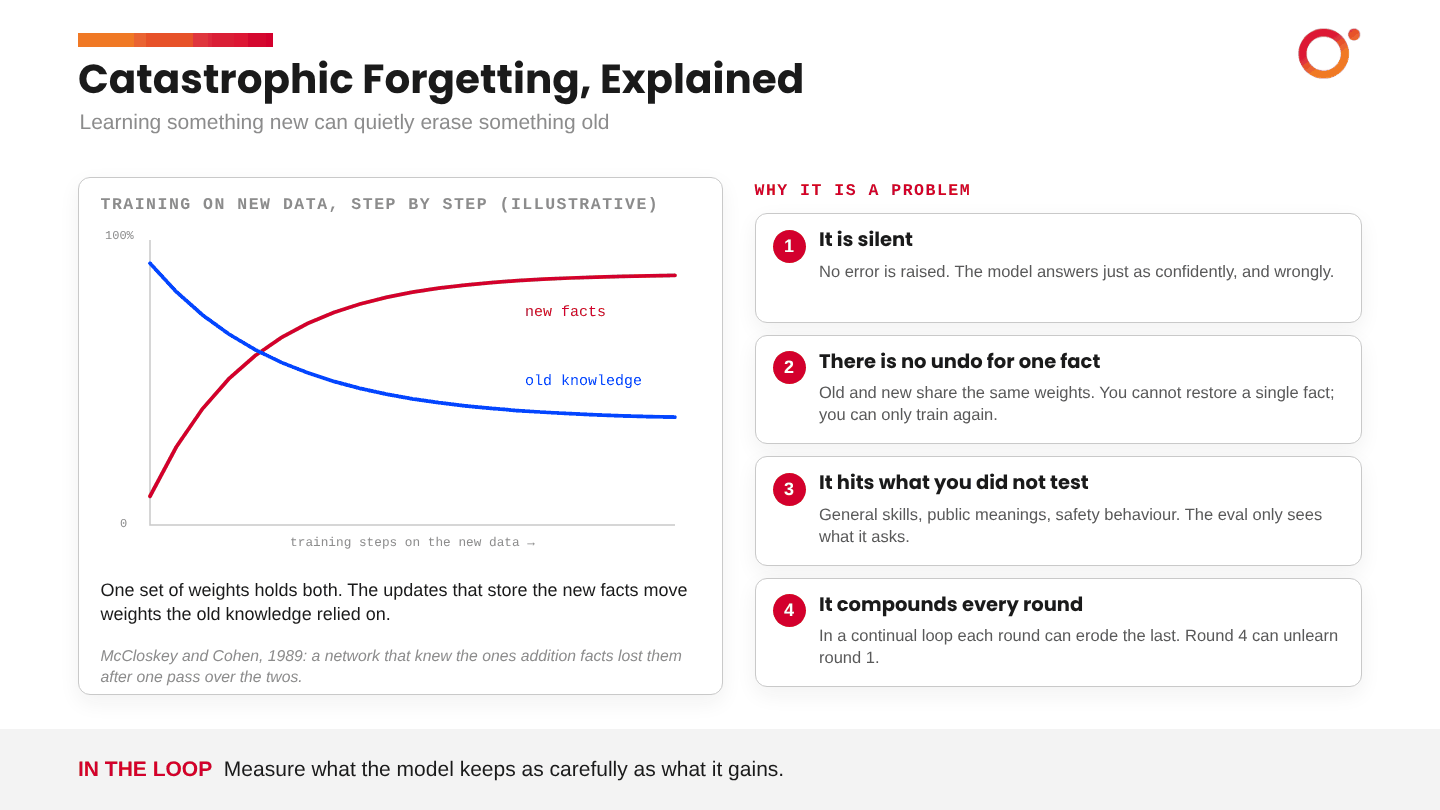

*Figure 4. New facts go up, old knowledge can come down, and no error is raised. The chart is illustrative.*

LoRA softens the problem. The 27.4 billion base weights stay frozen and only a small adapter trains, so general ability is well protected. But in this loop, **round 1's Calderwood knowledge lives in the adapter**, and round 2 trains that same adapter. Inside the adapter, the old problem is back.

## The brain's answer: two systems and replay

Brains face the same dilemma: learn a new episode in one exposure, yet keep decades of knowledge stable. The theory of **complementary learning systems** (McClelland, McNaughton and O'Reilly, 1995) says the brain solves it with two systems that learn at different speeds.

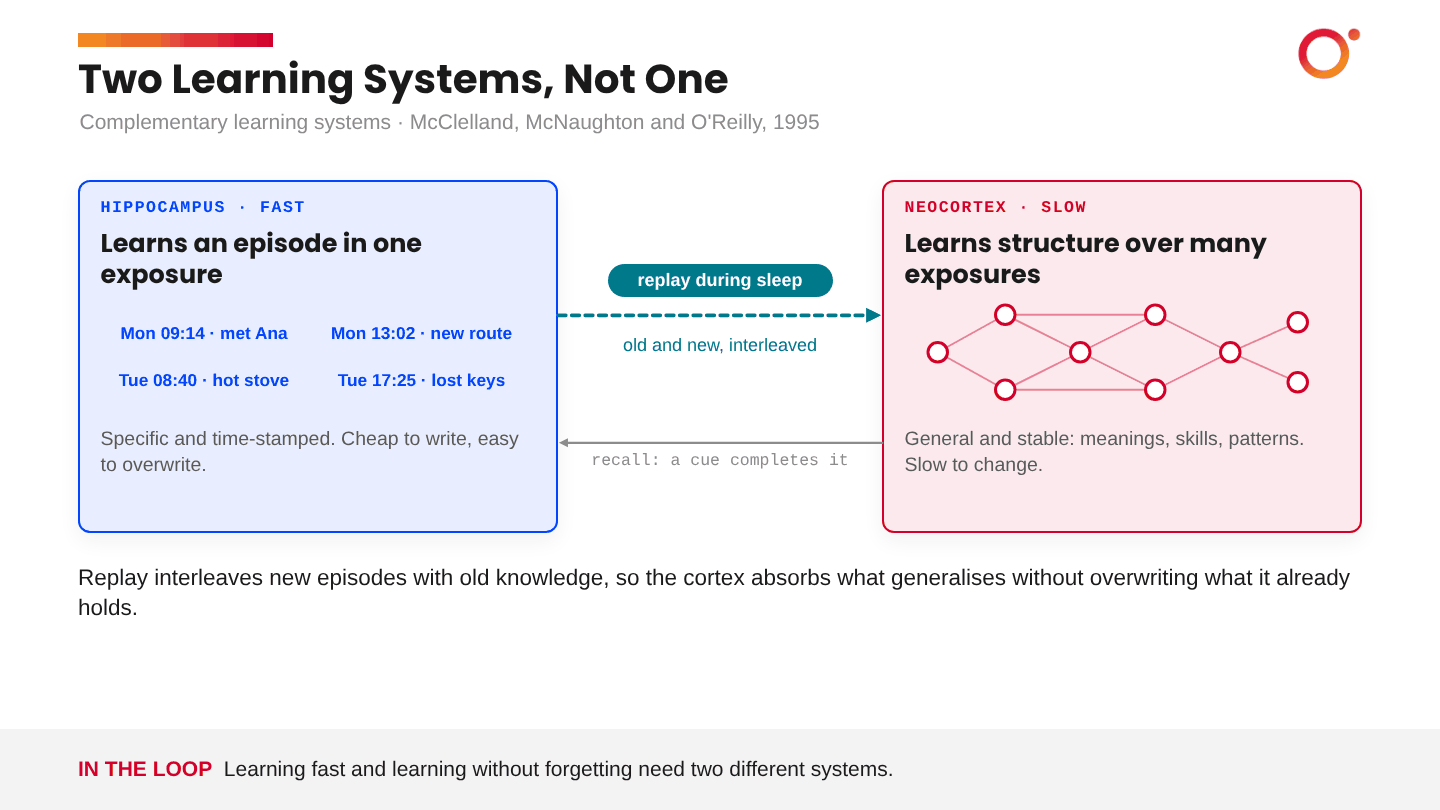

*Figure 5. A fast store that records single episodes, a slow learner that holds general knowledge, and replay between them. Old and new are interleaved, so the slow system absorbs the new without overwriting the old.*

The hippocampus records each episode quickly. During sleep it replays recent episodes to the neocortex, **interleaved with older ones**, and the neocortex slowly absorbs what generalises. The interleaving is the important detail: the slow system never trains on new material alone.

The mapping to an agent is direct:

| In the brain | In the agent | In this notebook |
|---|---|---|
| Hippocampus: fast episodic store | The memory store: traces and memory units | The `rounds/` data files |
| Neocortex: slow structural learning | The model weights, trained with LoRA | The adapter on Qwen3.5-27B |
| Replay during sleep | A refine cycle on the store, then scheduled fine-tuning | One training round |
| Interleaving old memories with new | Replay rows mixed into each round | Arm B |

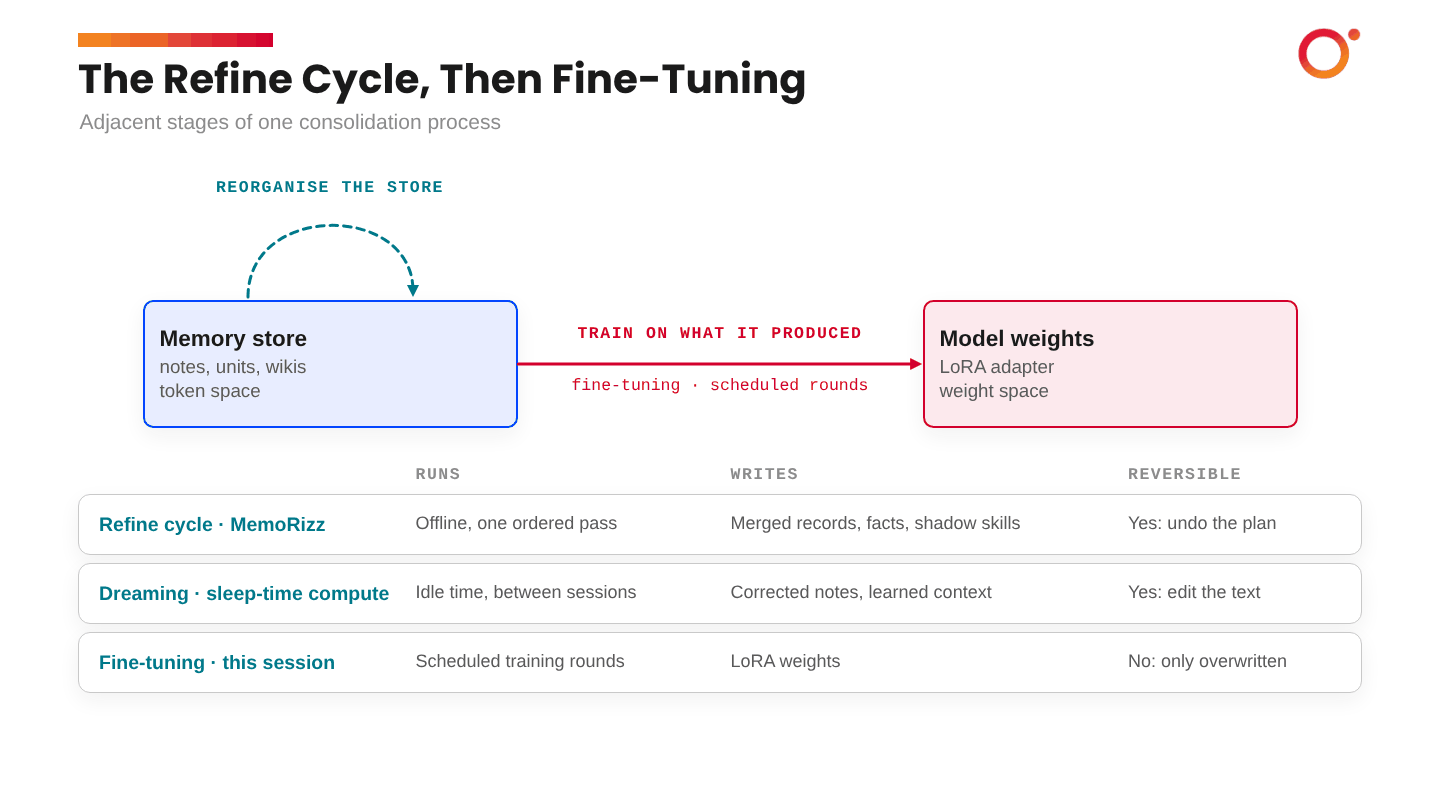

*Figure 6. Two adjacent stages of consolidation. A refine cycle reorganises the store and can be undone. Fine-tuning trains on what the store holds and can only be overwritten.*

## Ways to limit forgetting

| Defence | The idea | Cost |
|---|---|---|
| **Replay** | Mix a share of earlier rows into each round, so old knowledge is rehearsed while new knowledge is learned | Longer rounds; you must keep the old rows and filter out stale ones |
| **Gentler training** | A lower learning rate, fewer epochs or a smaller rank | New facts may not stick |
| **Regularisation** | Penalise changes to the weights that mattered for earlier rounds (elastic weight consolidation), or penalise answers that drift from the previous model's | More machinery and one more setting to tune |
| **Separate adapters** | One adapter per round or per domain, so rounds never share an update | Nothing is forgotten, but something has to choose which adapter answers |

This notebook tests the first one, because it is the simplest and the closest to what the brain does.

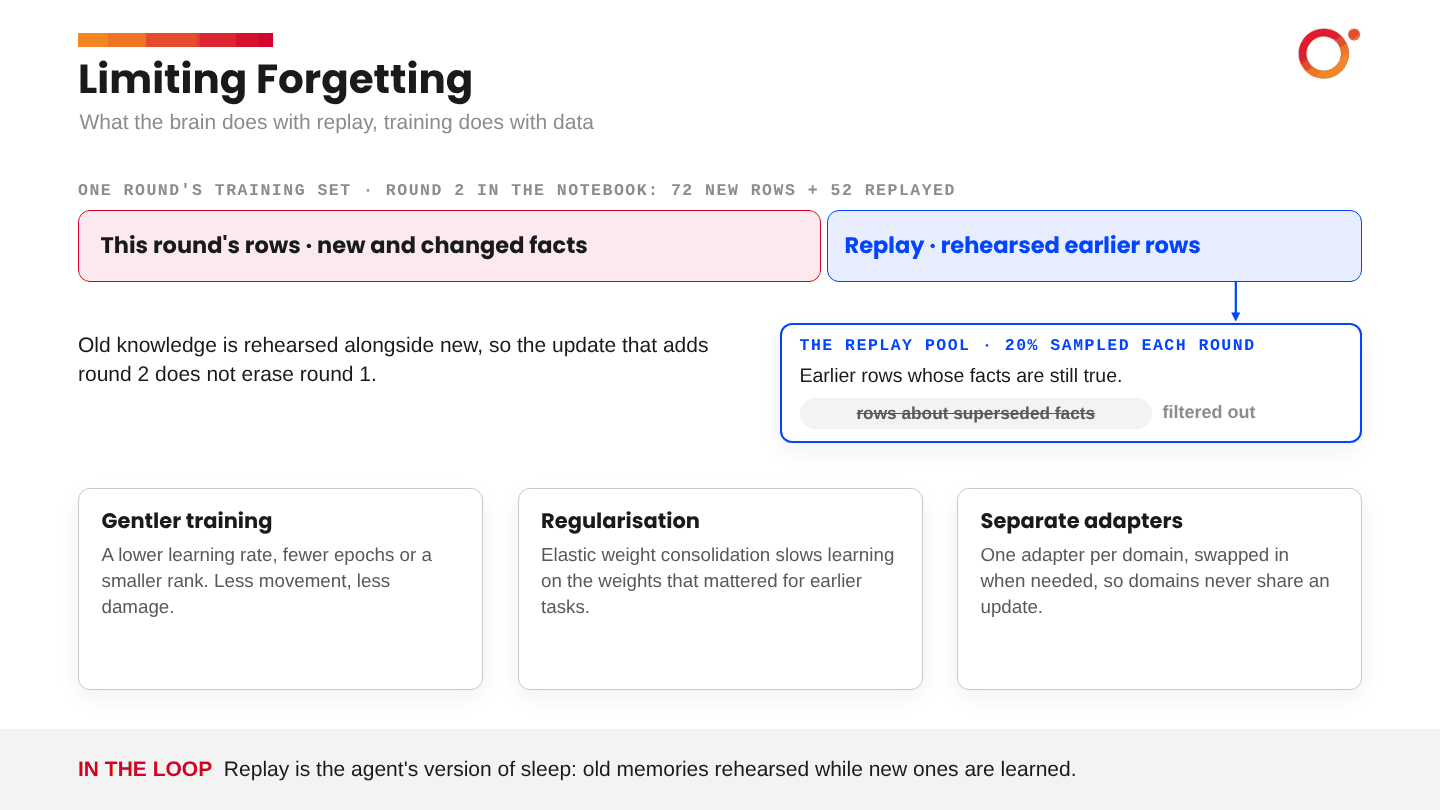

*Figure 7. A replay round's training set, drawn to scale for round two of this notebook: 72 new rows plus 52 replayed, a 20% sample of the pool of earlier rows. The other defences sit underneath.*

## See it happen in a toy model

Before spending an hour of GPU time, watch forgetting and replay in a model small enough to run in a second. The next cell builds a toy memory: one weight matrix that learns to map random "questions" (vectors of 24 numbers) to one of 8 "answers".

- **Round 1** teaches it 30 facts.
- **Round 2** teaches it 30 new facts, and the cell tries four versions: no replay, then replaying 20%, 50% and 100% of the round-1 facts alongside the new ones.

| Name in the cell | What it is |
|---|---|
| `d = 24` | How many numbers describe each question. It limits how many facts the matrix can hold apart |
| `classes = 8` | How many possible answers there are. Guessing would score about 12% |
| `n = 30` | Facts per round |
| `steps`, `lr` | Training steps and learning rate for plain gradient descent on the cross-entropy loss |
| `fraction` | The share of round-1 facts replayed during round 2 |

**Predict first.** After round 2 with no replay, what will the model score on the round-1 facts: still 100%, about half, or close to guessing?

In [ ]:
import numpy as np

def make_facts(n, d, classes, rng):
    keys = rng.normal(size = (n, d))
    keys /= np.linalg.norm(keys, axis = 1, keepdims = True)
    return keys, rng.integers(0, classes, size = n)

def train(W, keys, values, steps = 300, lr = 2.0):
    for _ in range(steps):
        logits = keys @ W.T
        p = np.exp(logits - logits.max(axis = 1, keepdims = True))
        p /= p.sum(axis = 1, keepdims = True)
        p[np.arange(len(values)), values] -= 1          # gradient of the cross-entropy loss
        W = W - lr * (p.T @ keys) / len(values)
    return W

def accuracy(W, keys, values):
    return ((keys @ W.T).argmax(axis = 1) == values).mean()

rng = np.random.default_rng(0)
d, classes, n = 24, 8, 30
k1, v1 = make_facts(n, d, classes, rng)     # round 1's facts
k2, v2 = make_facts(n, d, classes, rng)     # round 2's facts

W1 = train(np.zeros((classes, d)), k1, v1)
print(f"after round 1:               round-1 facts {accuracy(W1, k1, v1):4.0%}")

for fraction in (0.0, 0.2, 0.5, 1.0):
    picked = rng.choice(n, int(fraction * n), replace = False)     # the replay sample
    keys, values = np.vstack([k2, k1[picked]]), np.concatenate([v2, v1[picked]])
    W2 = train(W1.copy(), keys, values)
    print(f"after round 2, replay {fraction:4.0%}:  round-1 facts {accuracy(W2, k1, v1):4.0%}   round-2 facts {accuracy(W2, k2, v2):4.0%}")

Three things to take from the output.

1. **Without replay, round 1 falls to well under half**, even though nothing in round 2 contradicts it. The new facts simply reused the weights.
2. **Replay brings round 1 back**, and more replay brings back more.
3. **In this toy, replay protects little beyond the facts it replays.** The facts are random and share nothing, so rehearsing one does not help its neighbours. A language model's rows share a great deal: the same system prompt, the same style of answer, overlapping vocabulary. That is the reason a small sample can protect more than its share in practice, and the retention grid in Part 11 measures whether it did in your run.

---
# Part 3: The use case over time

## Calderwood, recapped

**Calderwood Insurance** is a fictional UK insurer. Its claims handlers ask an internal support assistant about systems (Beacon, Atlas, Tally), abbreviations, error codes, status codes and approval limits. Much of that knowledge is in senior people's heads and not in the official knowledge base, so the agent learns it on the job: a handler asks, the knowledge base has nothing, a senior colleague answers, and the agent writes a memory.

Every name is invented, which means the base model cannot know any of it. Five acronyms deliberately collide with real insurance terms (at Calderwood, TPA means Total Payout Authority, not Third Party Administrator).

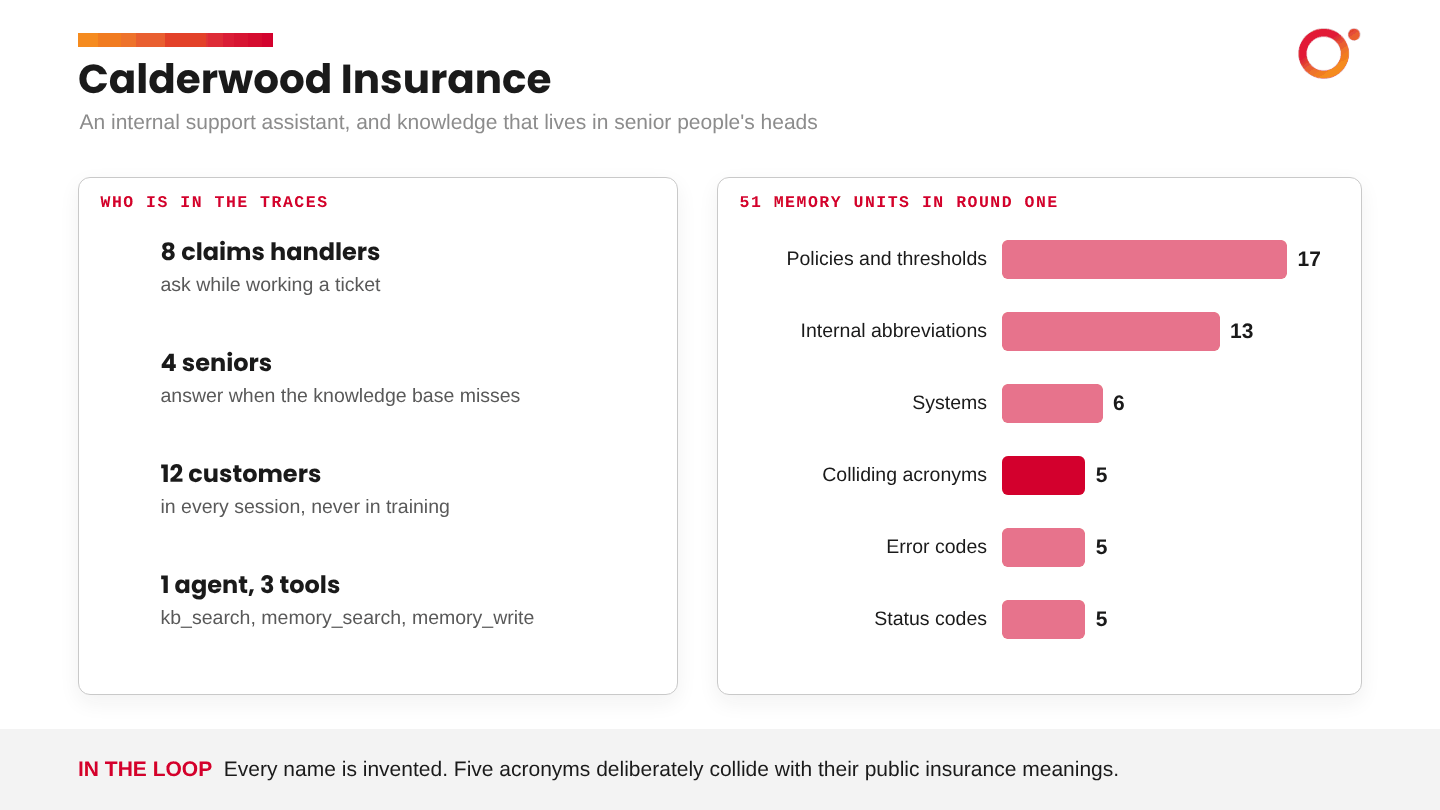

*Figure 8. Who appears in the traces, and the 51 memory units of round one. This is the repaired dataset, with two more policies and one more status code than the first run used.*

Each fact goes through the same stages on its way to the weights: a **trace** of the session, a **memory unit** extracted from it, and several **training rows**, each a full chat, that ask about the unit in different words. A fourth piece sits beside them: one **held-out question** per fact that the model never sees in training.

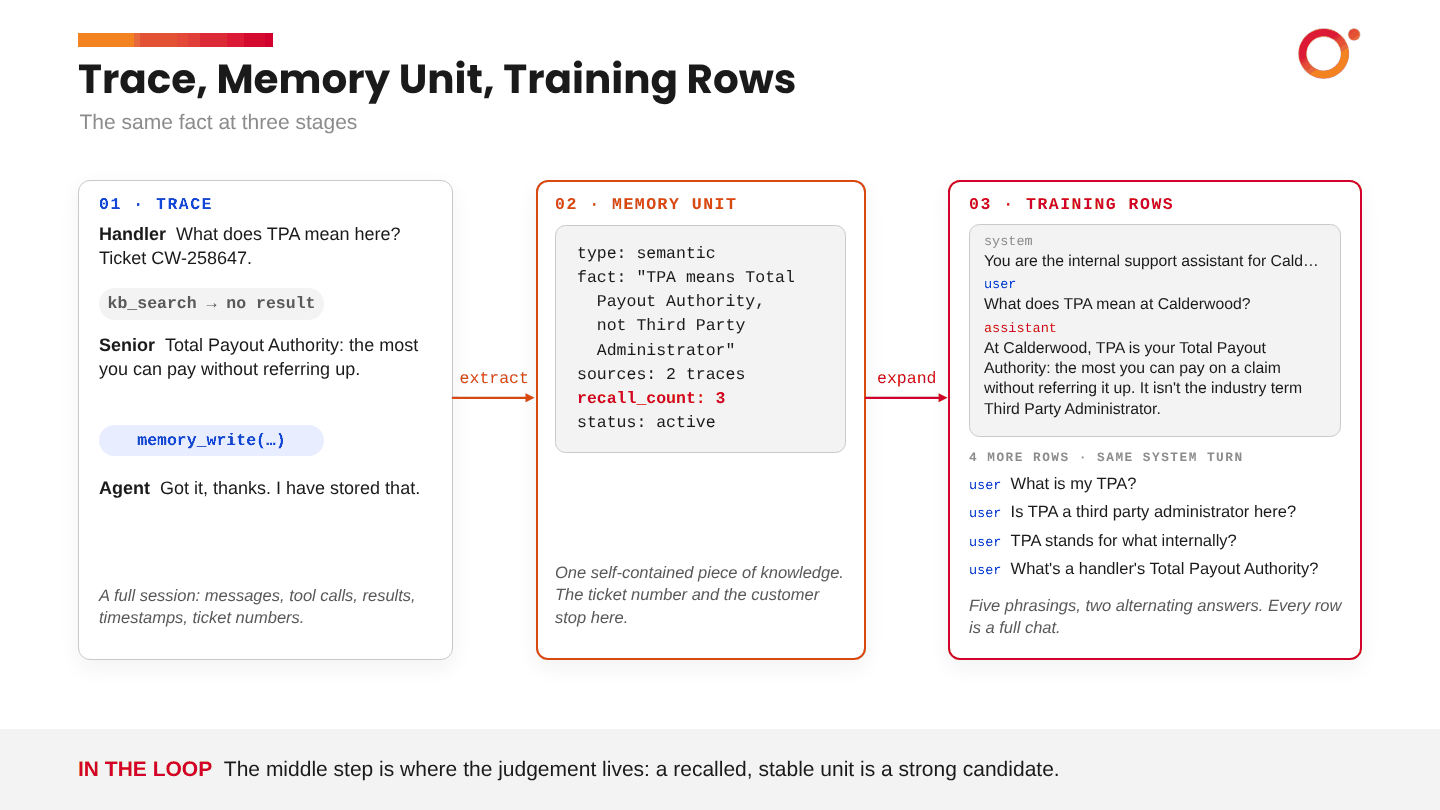

*Figure 9. One fact as a trace, a memory unit and training rows. Every round in this notebook has its own files for each stage, plus its held-out questions.*

## Three rounds

The agent keeps working after the first fine-tune, and the business keeps changing.

| Round | When | What is new | What changed | Traces | New units | Train rows | Held-out questions |
|---|---|---|---|---|---|---|---|
| 1 | Sept to Oct 2026 | The Calderwood baseline | Nothing | 40 | 51 | 279 | 64 |
| 2 | Jan 2027 | Compass (a customer-facing claims tracker), the Digital Support Desk, a settlement review step, new error and status codes, one more colliding acronym (NPS) | 3 facts | 10 | 13 | 72 | 16 |
| 3 | Apr 2027 | Motor Hub, the Policy Excess Ledger, Beacon Mobile, Harbour Line, another collision (RTA) | 2 facts | 10 | 11 | 61 | 14 |

Rounds 2 and 3 are much smaller than round 1. That is typical: the first consolidation moves a backlog, and later rounds move what has arrived since.

## The five facts that change

| Fact | Round 1 value | New value | Changes in |
|---|---|---|---|
| Grade 1 handler's payout limit (TPA) | £2,500 | £3,000 | Round 2 |
| Deadline for an Amber Pack to reach the Counter Fraud Unit | 2 working days | 3 working days | Round 2 |
| How customers upload large files | Drop | Compass (Drop is retired) | Round 2 |
| Deadline to settle a motor total loss | 10 working days | 7 working days | Round 3 |
| Response time for Premier Commercial Lines customers | 2 working hours | 1 working hour | Round 3 |

Four of the five are a number that moves a little. Those are hard for a model: the question is the same, the old answer was trained in firmly, and the new answer differs by one token.

## Forget, don't delete

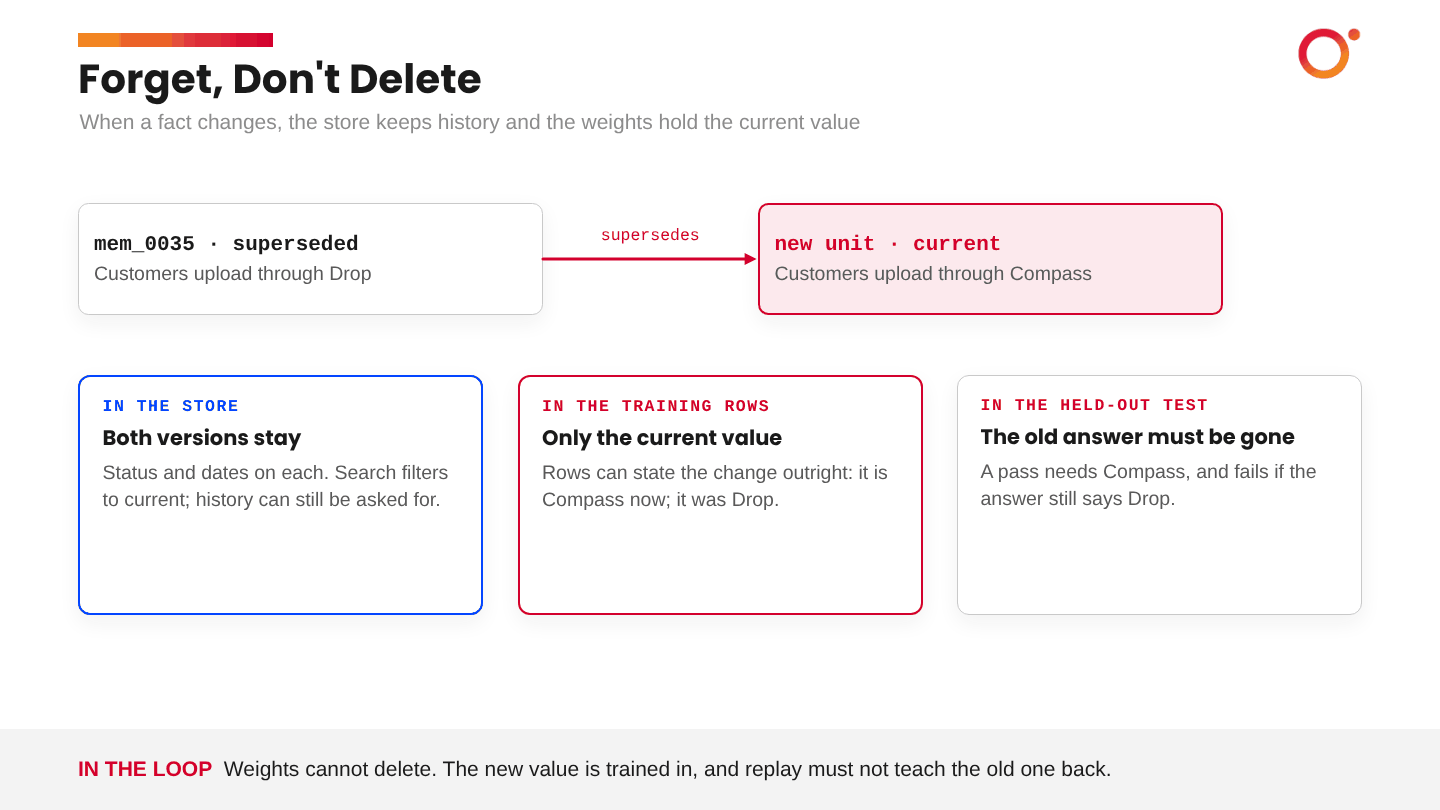

*Figure 10. What happens to a changed fact in each place. The store keeps the history, the training rows carry only the current value, and the test checks that the old answer is gone.*

A changed fact is handled differently in each space.

- **In the store (token space),** the old unit is not deleted. It is marked `superseded`, and it points to the unit that replaced it. The history stays available for audit, and search simply filters on `status = active`.
- **In the weights,** there is no such thing as marking a value as old. The new value has to be trained in until it wins. The round's training rows therefore teach the current value, and for the four numeric changes they never mention the old number.
- **In the test,** the changed fact's question passes only when the new value is present and the old value is absent.

One consequence for the test set: a round-1 question about the Grade 1 limit expects £2,500, which becomes the wrong answer in round 2. Such questions are **retired** from round 1's set from that round on, and the changed fact's own question (in round 2 or 3) takes over.

---
# Part 4: Setup

## Install the libraries

The same stack as the first notebook. `%%capture` hides the installer's output. Run it once per session; it takes a few minutes.

| Library | Role |
|---|---|
| `torch` | PyTorch, the tensor and training framework underneath everything |
| `unsloth`, `unsloth_zoo` | A wrapper around the Hugging Face stack with faster kernels and lower memory use |
| `transformers` | Model and tokenizer classes |
| `trl` | Provides `SFTTrainer`, the supervised fine-tuning loop |
| `bitsandbytes`, `xformers`, `torchao` | Quantisation and efficient attention kernels |

In [ ]:
%%capture
import os, importlib.util
!pip install --upgrade -qqq uv
if importlib.util.find_spec("torch") is None or "COLAB_" in "".join(os.environ.keys()):
    try: import numpy, PIL; _numpy = f"numpy=={numpy.__version__}"; _pil = f"pillow=={PIL.__version__}"
    except: _numpy = "numpy"; _pil = "pillow"
    !uv pip install -qqq \
        "torch==2.8.0" "triton>=3.3.0" {_numpy} {_pil} torchvision "torchaudio==2.8.0" bitsandbytes xformers==0.0.32.post2 \
        "unsloth_zoo[base] @ git+https://github.com/unslothai/unsloth-zoo" \
        "unsloth[base] @ git+https://github.com/unslothai/unsloth"
    !uv pip install -qqq --no-deps "torchcodec==0.7.0"
elif importlib.util.find_spec("unsloth") is None:
    !uv pip install -qqq unsloth
!uv pip install --upgrade --no-deps "tokenizers>=0.22.0,<=0.23.0" trl==0.22.2 unsloth unsloth_zoo
!uv pip install transformers==5.3.0
!unsloth install-kernels
!uv pip install --no-deps --upgrade "torchao>=0.16.0"

The install cell hides its output, so it also hides its failures. Colab updates its base image often, and when a pinned version no longer installs, a package can go missing without any message. The next cell checks that the packages the notebook needs are importable, installs any that are missing, and prints the versions you ended up with.

In [ ]:
import importlib.util, importlib.metadata, subprocess, sys

needed = ["unsloth", "unsloth_zoo", "transformers", "trl", "peft", "datasets", "bitsandbytes"]
missing = [p for p in needed if importlib.util.find_spec(p) is None]
if missing:
    print("Missing after the install cell:", missing, "-> installing now")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing])
    importlib.invalidate_caches()

still = [p for p in needed if importlib.util.find_spec(p) is None]
for p in needed + ["torch"]:
    try:
        print(f"{p:<14} {importlib.metadata.version(p)}")
    except Exception:
        print(f"{p:<14} NOT INSTALLED")
print("\nAll packages present." if not still else f"\nStill missing: {still}. Install them before going on.")

## The settings

Every knob of the experiment is in one cell, so a second run with different values is a one-line change.

| Setting | Value here | What it controls |
|---|---|---|
| `QUICK` | `False` | `True` scores a fixed subset of questions per round instead of all of them. Use it for a fast first pass; the numbers are noisier and a changed fact may not be in the subset |
| `QUICK_N` | `12` | How many questions per round `QUICK` scores |
| `EPOCHS` | `2` | Passes over each round's rows. The first run used 3 and ended at a training loss of 0.075, which is memorisation territory, so fewer epochs is the first thing to try |
| `REPLAY_FRACTION` | `0.2` | In Arm B, the share of the eligible earlier rows mixed into each round. 10 to 20% is a common starting range |
| `LEARNING_RATE` | `2e-4` | The size of each weight update, the same in every round. Lowering it for later rounds is one of the experiments suggested at the end |
| `RUN_BASELINE` | `False` | `True` also scores the untouched base model on all three rounds' questions before any training |

The cell also imports the standard-library modules the notebook uses and `pandas` for tables.

In [ ]:
import os, zipfile, json, math, random, time
import pandas as pd

QUICK = False          # True: 12 held-out questions per round instead of all of them
QUICK_N = 12
EPOCHS = 2             # the first run used 3
REPLAY_FRACTION = 0.2  # share of the earlier-rounds pool mixed into each replay round
LEARNING_RATE = 2e-4
RUN_BASELINE = False   # True: also score the untouched base model on every round's questions first

## Upload and load the data

In Colab, open the **Files** panel and drag `calderwood_data_v2.zip` onto the root folder. The next cell unzips it and checks that each round has its four files.

| File | What it holds |
|---|---|
| `rounds/round{1,2,3}_traces.jsonl` | The agent's sessions in that period |
| `rounds/round{1,2,3}_memory_units.jsonl` | The memory units extracted from those sessions |
| `rounds/round{1,2,3}_train.jsonl` | The training rows built from those units |
| `rounds/round{1,2,3}_eval.jsonl` | The held-out questions for that round |
| `rounds/memory_store_after_round3.jsonl` | The whole store at the end: every unit, with its status |
| `rounds/manifest.json` | A summary of the rounds, and which round-1 questions are retired when |

What the cell builds:

| Name | What it is |
|---|---|
| `ROUNDS` | `[1, 2, 3]` |
| `train_rows[r]`, `eval_items[r]` | Round `r`'s training rows and held-out questions |
| `store` | The memory store after round 3 |
| `superseded_in` | A dictionary from a fact's id to the round in which it was replaced, such as `{"drop": 2}`. Part 8 uses it to filter the replay pool |

In [ ]:
if os.path.exists("calderwood_data_v2.zip"):
    zipfile.ZipFile("calderwood_data_v2.zip").extractall(".")
for r in (1, 2, 3):
    for part in ("traces", "memory_units", "train", "eval"):
        assert os.path.exists(f"rounds/round{r}_{part}.jsonl"), f"Missing rounds/round{r}_{part}.jsonl: upload calderwood_data_v2.zip first"

ROUNDS = [1, 2, 3]
manifest   = json.load(open("rounds/manifest.json"))
train_rows = {r: [json.loads(l) for l in open(f"rounds/round{r}_train.jsonl")] for r in ROUNDS}
eval_items = {r: [json.loads(l) for l in open(f"rounds/round{r}_eval.jsonl")] for r in ROUNDS}
store      = [json.loads(l) for l in open("rounds/memory_store_after_round3.jsonl")]

# fact id -> the round in which it was superseded
superseded_in = {}
for r in ROUNDS:
    for it in eval_items[r]:
        if it.get("supersedes"):
            superseded_in[it["supersedes"]] = r

print(pd.DataFrame(manifest["rounds"])[["round", "label", "traces", "new_memory_units", "changed_facts", "train_rows", "eval_items"]].to_string(index=False))
print(f"\nmemory store after round 3: {len(store)} units, {sum(u['status'] == 'superseded' for u in store)} superseded (kept, not deleted)")

Check the printed table against the one in Part 3. The last line should report 75 units in the store, 5 of them superseded and none deleted.

The next cell lists those five, each beside the unit that replaced it.

In [ ]:
by_id = {u["memory_id"]: u for u in store}
for old in store:
    if old["status"] == "superseded":
        new = by_id[old["superseded_by"]]
        print(f'{old["memory_id"]} (superseded): {old["content"]}')
        print(f'{new["memory_id"]} (active)    : {new["content"]}\n')

---
# Part 5: Follow one changed fact through the pipeline

Before any training, trace Drop's retirement from end to end. This is the part of the pipeline that a single fine-tune never needs.

## What to look for

The next cell prints four things.

1. **The trace.** A handler asks how a customer can send large files. The agent recalls its old unit about Drop, answers from it, and asks whether it is still current. A senior handler corrects it: Drop has gone, and everything now comes through Compass. The agent then calls a tool the first notebook did not have: **`memory_update`**. Its arguments include `supersedes`, the id of the unit being replaced.
2. **The two units in the store.** The old one has `status: "superseded"` and a `superseded_by` pointer. The new one has `status: "active"` and a `supersedes` pointer back.
3. **The round-2 training rows for the new unit.** In several phrasings, they say that Drop has been retired and give Compass as the answer. None of them tells the model to use Drop.
4. **The held-out question for the changed fact.** It has two fields that matter:

| Field | Meaning |
|---|---|
| `must_include` | Groups of key terms. Every group needs at least one of its alternatives in the answer |
| `must_exclude` | Groups of key terms that must **not** appear. For a changed fact, this is the old value |
| `supersedes` | The id of the fact this one replaces |

The last line printed is the list of round-1 questions that are retired, and the round in which each stops being asked.

In [ ]:
traces2 = [json.loads(l) for l in open("rounds/round2_traces.jsonl")]
t = next(t for t in traces2 if any(e.get("tool") == "memory_update" and "Drop" in json.dumps(e) for e in t["events"]))
i = next(i for i, e in enumerate(t["events"]) if e.get("tool") == "memory_update" and e["type"] == "tool_call")
print("=== TRACE", t["trace_id"], "===")
for e in t["events"][i-5:i+3]:
    if e["type"] == "message":
        print(f'{e["sender"]:>26}: {e["content"]}')
    else:
        print(f'{"":>26}  [{e["type"]}: {e["tool"]}] {json.dumps(e.get("args", e.get("content")), ensure_ascii=False)[:200]}')

new_id = t["events"][i+1]["content"]["memory_id"]
old_id = t["events"][i]["args"]["supersedes"]
print("\n=== MEMORY STORE: old and new unit ===")
for u in store:
    if u["memory_id"] in (old_id, new_id):
        print(json.dumps({k: u[k] for k in ("memory_id", "status", "supersedes", "superseded_by", "content") if k in u}, indent=2, ensure_ascii=False))

print("\n=== ROUND 2 TRAINING ROWS for", new_id, "===")
for r in train_rows[2]:
    if r["memory_id"] == new_id:
        print("Q:", r["conversations"][1]["content"]); print("A:", r["conversations"][2]["content"], "\n")

print("=== EVAL ITEM for the changed fact ===")
it = next(it for it in eval_items[2] if it.get("supersedes") == "drop")
print(json.dumps({k: it[k] for k in ("id", "category", "question", "must_include", "must_exclude", "supersedes")}, indent=2, ensure_ascii=False))
print("\nRound-1 items that get retired when their fact changes:", manifest["superseded_round1_eval_items"])

Read the `must_exclude` list for Drop closely. It does not ban the word "Drop" outright; it bans phrases such as "through Drop" and "use Drop". An answer that says "Drop was retired, use Compass" is correct and should pass, so the exclusion targets the ways of recommending Drop and not the name.

For the four numeric changes there is no such room. Their `must_exclude` is the old number itself.

---
# Part 6: The model and the adapter

The model and LoRA settings are the same as in the first notebook, which explains them from the ground up. A short recap follows, so that each setting has its meaning beside the cell.

## Loading the model

`FastLanguageModel.from_pretrained` downloads the weights (about 54GB, a few minutes) and returns the model and its tokenizer.

| Parameter | Value here | What it means |
|---|---|---|
| `model_name` | `"unsloth/Qwen3.5-27B"` | The model to download from the Hugging Face Hub |
| `max_seq_length` | `2048` | The most tokens one training row may hold. Calderwood rows are far shorter |
| `load_in_4bit` | `False` | `True` would load a 4-bit base (about 13.5GB) and make this a QLoRA run |
| `load_in_8bit` | `False` | `True` would load an 8-bit base (about 27GB) |
| `full_finetuning` | `False` | Keep the base weights frozen so LoRA can be attached |

With the three flags `False`, the model loads in plain 16-bit: 27.4 billion parameters at 2 bytes each, about 54GB.

## Which GPU did you get?

The notebook is written for an 80GB card. Colab does not always give you one, so check before downloading 54GB of weights.

In [ ]:
import subprocess

try:
    out = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader,nounits"],
                         capture_output = True, text = True).stdout.strip().splitlines()[0]
    name, mib = [x.strip() for x in out.split(",")]
    gib = int(mib) / 1024
    print(f"GPU: {name}, {gib:.1f} GiB")
    if gib >= 60:
        print("Enough for the notebook as written: 16-bit weights.")
    elif gib >= 35:
        print("Not enough for 16-bit. In the loading cell set load_in_4bit = True (or load_in_8bit = True).")
    elif gib >= 21:
        print("Set load_in_4bit = True in the loading cell. If training runs out of memory, use batch size 2 with gradient accumulation 4.")
    else:
        print("Too small for this model. Change the runtime type.")
except Exception as e:
    print("No GPU found. Change the runtime type to a GPU before going on.", e)

| Card | Shows as | Loading setting | Weights on the GPU | Notes |
|---|---|---|---|---|
| A100 80GB | about 80 GiB | As written (all three flags `False`) | about 51 GiB | What the notebook assumes |
| A100 40GB | about 40 GiB | `load_in_4bit = True`, or `load_in_8bit = True` | roughly 14 to 20 GiB in 4-bit, about 27 GiB in 8-bit | 4-bit is the standard QLoRA route and leaves the most headroom. 8-bit is slower, which matters over six training rounds |
| L4 | about 22.5 GiB | `load_in_4bit = True` | roughly 14 to 20 GiB | Only a few GiB spare for training. The replay rounds are no larger per step than the others, so the same batch settings apply |

Colab's resource panel shows GiB under the label "GB". Both arms must use the same loading setting, or the comparison between them means nothing.

In [ ]:
from unsloth import FastLanguageModel
import torch

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/Qwen3.5-27B",
    max_seq_length = 2048,
    load_in_4bit = False,
    load_in_8bit = False,
    full_finetuning = False,
)

**Only if you loaded in 8-bit.** The 8-bit layers work in float16 while the rest of the model passes bf16 numbers, so every layer logs a line saying it is converting its input: `MatMul8bitLt: inputs will be cast from torch.bfloat16 to float16`. It is harmless, and it prints once per layer per generated token, which floods the output across the hundreds of questions this notebook scores. The next cell silences it. It does nothing on a 16-bit or 4-bit load.

In [ ]:
import logging, warnings

logging.getLogger("bitsandbytes.autograd._functions").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message = ".*MatMul8bitLt.*")

## Attaching the adapter

LoRA leaves each chosen weight matrix $W$ frozen and trains a small correction beside it, made of two thin matrices:

$$y = W x + \frac{\alpha}{r} \, B A x$$

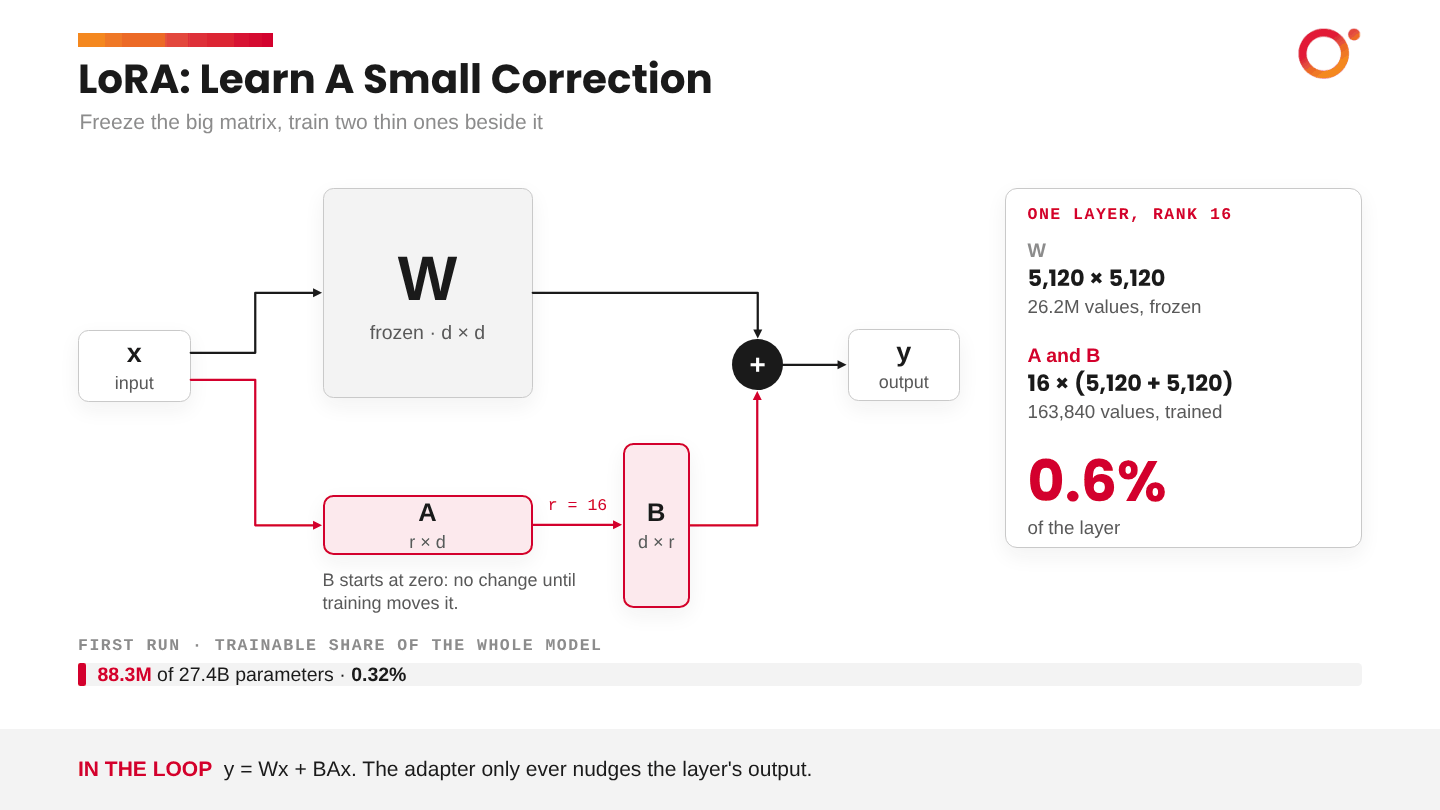

*Figure 11. The frozen path on top, the adapter path underneath. Only A and B train: about 0.3% of the model.*

| Parameter | Value here | What it means |
|---|---|---|
| `r` | `16` | The rank: how many independent directions of change the adapter can learn |
| `target_modules` | eight names | Which matrices in each block get an adapter: the attention projections (`q_proj`, `k_proj`, `v_proj`, `o_proj`, `out_proj`) and the MLP projections (`gate_proj`, `up_proj`, `down_proj`) |
| `lora_alpha` | `32` | Scales the update by `lora_alpha / r`, so 2 here |
| `lora_dropout` | `0` | No dropout on the adapter's input |
| `bias` | `"none"` | Bias terms stay frozen |
| `use_gradient_checkpointing` | `"unsloth"` | Recompute some activations in the backward pass to save memory |
| `random_state` | `3407` | The seed for initialising $A$ |
| `use_rslora` | `False` | Rank-stabilised scaling, not needed at rank 16 |
| `loftq_config` | `None` | An initialisation for quantised bases, not used here |

Two properties of the adapter matter more in a loop than in a single run.

**It starts as a no-op.** $A$ starts random and $B$ starts at zero, so $BA = 0$ and a fresh adapter leaves the model exactly as it was. Part 9 uses this to put the model back to its starting point between the two arms without reloading 54GB.

**It is one adapter, trained three times.** Each round continues from the previous round's $A$ and $B$. The adapter's capacity is fixed at rank 16, so round 2's facts have to share it with round 1's. The paper *LoRA Learns Less and Forgets Less* found that LoRA damages the base model's knowledge less than full fine-tuning does. That protects general ability. It does not protect what earlier rounds wrote into the adapter itself.

In [ ]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 16,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj",
                      "out_proj",],
    lora_alpha = 32,
    lora_dropout = 0,
    bias = "none",
    use_gradient_checkpointing = "unsloth",
    random_state = 3407,
    use_rslora = False,
    loftq_config = None,
)

---
# Part 7: The evaluation harness, extended for a loop

A single run needs one comparison: before and after. A loop needs the same questions asked again after every round, with the rules of the test changing as facts change. The harness from the first notebook gets three additions:

1. `score` learns about `must_exclude`.
2. `active_items` knows which questions are still valid after a given round.
3. `evaluate` scores every round so far and keeps the item-level results for the grid.

Everything else stays fixed across rounds and across arms: the same system prompt, greedy decoding, thinking off. If any of those changed between two measurements, the difference could not be put down to training.

## Scoring a changed fact

**Key-term scoring** passes an answer when every group in `must_include` has at least one of its alternatives present. Three helpers do the work:

- `normalise` lowercases the text and strips commas from numbers, so "£2,500" becomes "£2500".
- `_pattern` stops a number matching inside a longer one, so "£250" does not match "£2500".
- `_has` checks whether one alternative appears in the answer.

The new rule in `score`: after the `must_include` check, if **any** alternative from **any** `must_exclude` group is present, the answer fails.

In [ ]:
import re


def normalise(text):
    text = text.lower().replace("’", "'")
    return re.sub(r"(?<=\d),(?=\d)", "", text)  # "£2,500" -> "£2500"


def _pattern(alt):
    p = re.escape(alt)
    if alt[0].isdigit():
        p = r"(?<!\d)" + p
    if alt[-1].isdigit():
        p = p + r"(?!\d)"  # so "£250" does not match "£2500"
    return p


def _has(text, alt):
    return re.search(_pattern(normalise(alt)), text) is not None


def score(answer, must_include, must_exclude=None):
    """Pass if every group in must_include has at least one alternative present,
    and no alternative in any must_exclude group is present (used for changed facts)."""
    a = normalise(answer)
    if not all(any(_has(a, alt) for alt in group) for group in must_include):
        return False
    for group in (must_exclude or []):
        if any(_has(a, alt) for alt in group):
            return False
    return True

Try it on the Grade 1 payout limit, which rises from £2,500 to £3,000 in round 2. Three answers: the new value, the old value, and an answer that gives both.

In [ ]:
must_include = [["£3000", "£3k", "3000"]]
must_exclude = [["£2500", "£2.5k", "2500"]]
answers = [
    "A Grade 1 handler's TPA is £3,000.",
    "A Grade 1 handler's TPA is £2,500.",
    "It was £2,500 until January 2027. It is now £3,000.",
]
for a in answers:
    print("PASS" if score(a, must_include, must_exclude) else "FAIL", "|", a)

The third answer is correct and still fails, because it mentions the old number. The scorer cannot tell "it was £2,500" from "it is £2,500". That strictness is deliberate: for a changed fact, the dangerous failure is the old value coming back, so the test is tuned to catch it at the price of some false negatives. It is also why the training answers for the numeric changes give only the new number.

When you read the results in Part 12, look at the actual answers for any changed fact that fails. A fail may be the old value, or a correct answer that happened to mention it.

## Asking the model

`ask` sends one conversation to the model and returns its answer. It is the same function as in the first notebook, with a slightly shorter answer budget.

| Parameter | Value here | What it means |
|---|---|---|
| `add_generation_prompt` | `True` | End the prompt with the assistant tag, so the model's next tokens are its answer |
| `tokenize`, `return_tensors`, `return_dict` | `True`, `"pt"`, `True` | Return PyTorch tensors of token ids that can be passed straight to `generate` |
| `enable_thinking` | `False` | No `<think>` block, so answers are short and comparable |
| `max_new_tokens` | `128` | The most tokens the model may produce for one answer |
| `do_sample` | `False` | **Greedy decoding**: always take the most likely next token, so the same prompt gives the same answer every time. A measurement needs that |
| `use_cache` | `True` | Keep the KV cache so each new token does not recompute the ones before it |

The last two lines slice off the prompt, decode only the new tokens, and drop anything before a closing `</think>` tag.

In [ ]:
def ask(messages, max_new_tokens = 128):
    msgs = [{"role": m["role"], "content": [{"type": "text", "text": m["content"]}]} for m in messages]
    inputs = tokenizer.apply_chat_template(
        msgs, add_generation_prompt = True, tokenize = True,
        return_tensors = "pt", return_dict = True, enable_thinking = False,
    ).to("cuda")
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens = max_new_tokens, do_sample = False, use_cache = True)
    text = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens = True)
    return text.split("</think>")[-1].strip()

## Which questions are still valid

`active_items(j, k)` returns round `j`'s questions that are still valid **after training round `k`**. A round-1 question carries a `superseded_in_round` field if its fact later changes; once `k` reaches that round, the question is dropped.

`_quick_pick` is only used when `QUICK = True`. It fixes the same 12 questions per round for the whole run, using a seeded random generator, so every measurement in a quick run is on the same subset.

In [ ]:
_quick_pick = {r: random.Random(100 + r).sample(range(len(eval_items[r])), min(QUICK_N, len(eval_items[r]))) for r in ROUNDS}

def active_items(j, k):
    """Round j's eval items that are still valid after training round k."""
    items = eval_items[j]
    if QUICK:
        items = [items[i] for i in sorted(_quick_pick[j])]
    return [it for it in items if not (it.get("superseded_in_round") and it["superseded_in_round"] <= k)]

**Predict first.** Round 1 has 64 questions. Three of its facts change in round 2 and two more in round 3. How many round-1 questions are asked after each round, and how many questions in total?

In [ ]:
for k in ROUNDS:
    counts = {f"round {j}": len(active_items(j, k)) for j in ROUNDS if j <= k}
    print(f"after round {k}: {counts}  total {sum(counts.values())}")

print("\nretired round-1 questions:", [(it["id"], f'from round {it["superseded_in_round"]}') for it in eval_items[1] if it.get("superseded_in_round")])

With `QUICK = False`, the three totals add up to the number of questions each arm scores over the whole experiment.

## Scoring every round so far

`evaluate(arm, k)` runs after training round `k`. It asks every valid question from rounds 1 to `k`, scores each answer, and stores one record per question.

| Argument or name | What it means |
|---|---|
| `arm` | A label for the results: `"naive"`, `"replay"` or `"base"` |
| `k` | The round that has just been trained. `0` means nothing has been trained yet |
| `rounds` | Which rounds' questions to ask. By default, every round up to `k` |
| `RESULTS[arm][k]` | Where the table of item-level results is kept. The grid and the metrics in Part 11 are computed from these tables, so every summary number can be traced back to individual answers |
| `results/{arm}_after_round{k}.jsonl` | The same records on disk, written as soon as each evaluation finishes |

`summary(df)` reduces one of those tables to passes, totals and a percentage for each round's questions.

In [ ]:
RESULTS = {}   # RESULTS[arm][k] -> DataFrame of item-level results for all rounds j <= k

def evaluate(arm, k, rounds = None):
    rounds = rounds or [j for j in ROUNDS if j <= k] or ROUNDS
    records, t0 = [], time.time()
    for j in rounds:
        items = active_items(j, k)
        for n, it in enumerate(items, 1):
            answer = ask(it["messages"])
            records.append({"arm": arm, "after_round": k, "round": j, "id": it["id"], "category": it["category"],
                            "question": it["question"], "answer": answer,
                            "passed": score(answer, it["must_include"], it.get("must_exclude"))})
        print(f"[{arm} after round {k}] round {j} questions: {sum(r['passed'] for r in records if r['round'] == j)}/{len(items)} passed")
    df = pd.DataFrame(records)
    os.makedirs("results", exist_ok = True)
    df.to_json(f"results/{arm}_after_round{k}.jsonl", orient = "records", lines = True, force_ascii = False)
    RESULTS.setdefault(arm, {})[k] = df
    print(f"  ({time.time() - t0:.0f}s)")
    return df


def summary(df):
    t = df.groupby("round")["passed"].agg(passed = "sum", total = "count")
    t["score"] = (t["passed"] / t["total"] * 100).round(0).astype(int)
    return t

---
# Part 8: Building each round's training set

## What goes into a round

In Arm A a round's training set is simply that round's rows. In Arm B it is that round's rows plus a **replay sample** drawn from all earlier rounds.

The sample is drawn from a filtered pool. Every training row carries `fact_ids`, the facts it teaches. A row is kept out of the pool if any of its facts has been superseded by the round being built. Without that filter, replay would rehearse "the Grade 1 limit is £2,500" in the same round that is trying to teach £3,000.

The next cell shows which round-1 rows are kept out of the round-2 pool.

In [ ]:
gone = {fact for fact, changed_in in superseded_in.items() if changed_in <= 2}
excluded = [x for x in train_rows[1] if set(x.get("fact_ids", [])) & gone]

print(f"Facts superseded by round 2: {sorted(gone)}")
print(f"{len(excluded)} of {len(train_rows[1])} round-1 rows are kept out of the round-2 replay pool. A few of them:\n")
for x in excluded[:4]:
    print("  Q:", x["conversations"][1]["content"])
    print("  A:", x["conversations"][2]["content"], "\n")

## `make_rows`, line by line

| Step in the function | What it does |
|---|---|
| `rows = list(train_rows[r])` | Start with the round's own rows |
| `gone` | The facts superseded in this round or earlier |
| `pool` | Every row from earlier rounds whose facts are all still true |
| `n = int(REPLAY_FRACTION * len(pool))` | The sample size: 20% of the pool with the default setting |
| `random.Random(3407 + r).sample(pool, n)` | Draw the sample with a fixed seed, so a rerun replays the same rows |
| `random.Random(r).shuffle(rows)` | Mix the replayed rows in with the new ones |

Two design choices to notice. The fraction is taken **of the pool**, not of the new round, so the replay sample grows as the pool of earlier knowledge grows. And the sample is **drawn once per round**: every epoch of that round sees the same replayed rows.

In [ ]:
def make_rows(r, replay = False):
    rows = list(train_rows[r])
    if replay and r > 1:
        gone = {f for f, rr in superseded_in.items() if rr <= r}
        pool = [x for rr in ROUNDS if rr < r for x in train_rows[rr] if not (set(x.get("fact_ids", [])) & gone)]
        n = int(REPLAY_FRACTION * len(pool))
        sample = random.Random(3407 + r).sample(pool, n)
        print(f"  replay: {n} rows sampled from {len(pool)} eligible earlier rows "
              f"({sum(len(train_rows[rr]) for rr in ROUNDS if rr < r) - len(pool)} excluded as superseded)")
        rows += sample
    random.Random(r).shuffle(rows)
    return rows

**Predict first.** The pool for round 2 is round 1's 279 rows minus the excluded ones you just saw. How many rows will Arm B train on in round 2, and will that be more or fewer than twice Arm A's 72?

The next cell builds every round's training set for both arms and counts the training steps. A **step** is one weight update. With a batch of 4 rows and gradients accumulated over 2 batches, one step covers 8 rows, so a round takes about `rows / 8` steps per epoch.

In [ ]:
def steps_for(n_rows, batch = 4, accumulation = 2):
    return math.ceil(math.ceil(n_rows / batch) / accumulation) * EPOCHS

plan = []
for arm, replay in (("naive", False), ("replay", True)):
    for r in ROUNDS:
        rows = make_rows(r, replay)
        own = sum(x["round"] == r for x in rows)
        plan.append({"arm": arm, "round": r, "rows": len(rows), "from this round": own,
                     "replayed": len(rows) - own, "steps": steps_for(len(rows))})
print()
print(pd.DataFrame(plan).to_string(index = False))

Two things stand out in the table.

- **In the replay arm, rounds 2 and 3 are roughly half replay.** A 20% sample of a large pool is about as big as a small new round. That is the price of replay: the later rounds take almost twice as many steps.
- **Rounds 2 and 3 are short.** In the naive arm they run for fewer than 20 steps each. The learning-rate warmup takes the first 5 of those, so a good share of a small round is spent warming up. Keep that in mind if a later round under-learns.

---
# Part 9: The training round and the two arms

## One training step, recapped

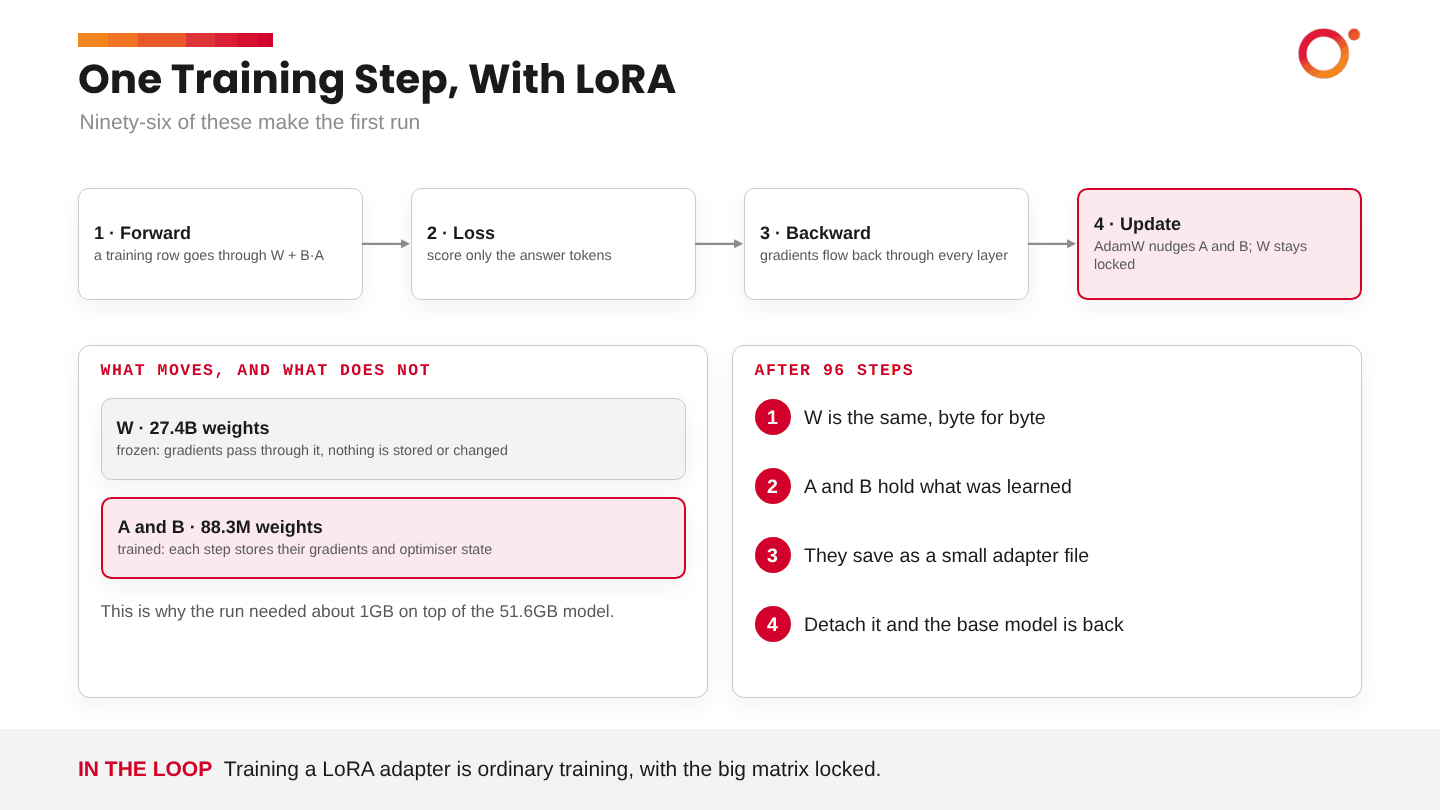

*Figure 12. Forward, loss, backward, update. The base weights are locked throughout; only A and B move, and they carry over from round to round.*

Each step runs a batch through the model, measures the **cross-entropy loss** on the answer tokens (how surprised the model was by the correct next token), sends gradients back, and nudges $A$ and $B$. Supervised fine-tuning is that loop, repeated.

## From rows to a dataset

`to_dataset` turns a list of rows into a Hugging Face `Dataset` and formats each conversation with the model's **chat template**: one string with `<|im_start|>` and `<|im_end|>` marking the system, user and assistant turns.

| Parameter | Value here | What it means |
|---|---|---|
| `tokenize` | `False` | Return a string; the trainer tokenises it later |
| `add_generation_prompt` | `False` | In training the string already holds the whole conversation, answer included |

## `train_round`: the settings

`train_round(rows, tag)` is the first notebook's trainer wrapped in a function, so it can be called six times.

| Parameter | Value here | What it means |
|---|---|---|
| `train_dataset` | `to_dataset(rows)` | This round's rows, formatted |
| `eval_dataset` | `None` | No evaluation inside the trainer. That would only compute a loss on reference answers; the harness from Part 7 does the more useful job after each round, making the model write an answer to every held-out question and checking it |
| `dataset_text_field` | `"text"` | The column that holds the formatted string |
| `dataset_num_proc` | `1` | Tokenise in a single process |
| `per_device_train_batch_size` | `4` | Four rows go through the GPU together |
| `gradient_accumulation_steps` | `2` | Add up gradients from two batches before one update: an effective batch of 8 |
| `warmup_steps` | `5` | Ramp the learning rate up from zero over the first 5 steps |
| `num_train_epochs` | `EPOCHS` (2) | Passes over the round's rows |
| `learning_rate` | `LEARNING_RATE` (2e-4) | The size of each update |
| `logging_steps` | `5` | Print the loss every 5 steps |
| `optim` | `"adamw_8bit"` | AdamW keeps running averages of each parameter's gradient to adapt its updates; the 8-bit version stores them compactly |
| `weight_decay` | `0.001` | A mild pull of the trained weights toward zero |
| `lr_scheduler_type` | `"linear"` | After warmup, lower the learning rate steadily to zero by the last step |
| `seed` | `3407` | Fixes the randomness, so a rerun gives the same result |
| `output_dir` | `f"outputs/{tag}"` | A separate checkpoint folder per arm and round |
| `report_to` | `"none"` | No external experiment tracker |

`train_on_responses_only` then masks everything before the assistant's turn, so the loss counts only the answer tokens. Its two arguments are the markers where a user turn and an assistant turn begin; they must match the chat template exactly.

## What carries over between rounds, and what does not

This is the detail that makes it a continual learning loop.

| | Between rounds of one arm |
|---|---|
| **The adapter weights $A$ and $B$** | **Carry over.** Round 2 starts from where round 1 finished |
| The optimiser's running averages | Start fresh. Each call builds a new `SFTTrainer` |
| The learning-rate schedule | Starts fresh: warmup, then a linear decay, in every round |
| The base model | Never changes |

The function switches the model to training mode at the start (`for_training`) and back to fast generation at the end (`for_inference`), so the evaluation that follows each round runs at full speed.

In [ ]:
from datasets import Dataset
from trl import SFTTrainer, SFTConfig
from unsloth.chat_templates import train_on_responses_only


def to_dataset(rows):
    ds = Dataset.from_list([{"conversations": x["conversations"]} for x in rows])
    return ds.map(lambda ex: {"text": [tokenizer.apply_chat_template(c, tokenize = False, add_generation_prompt = False)
                                       for c in ex["conversations"]]}, batched = True)


def train_round(rows, tag):
    FastLanguageModel.for_training(model)
    trainer = SFTTrainer(
        model = model, tokenizer = tokenizer, train_dataset = to_dataset(rows), eval_dataset = None,
        args = SFTConfig(
            dataset_text_field = "text", dataset_num_proc = 1,
            per_device_train_batch_size = 4, gradient_accumulation_steps = 2,
            warmup_steps = 5, num_train_epochs = EPOCHS, learning_rate = LEARNING_RATE,
            logging_steps = 5, optim = "adamw_8bit", weight_decay = 0.001,
            lr_scheduler_type = "linear", seed = 3407, output_dir = f"outputs/{tag}", report_to = "none",
        ),
    )
    trainer = train_on_responses_only(trainer, instruction_part = "<|im_start|>user\n", response_part = "<|im_start|>assistant\n")
    stats = trainer.train()
    print(f"  trained {len(rows)} rows in {stats.metrics['train_runtime']/60:.1f} min, final loss {stats.metrics.get('train_loss', float('nan')):.3f}")
    FastLanguageModel.for_inference(model)
    return stats

## Resetting between arms

Arm B has to start from the same place as Arm A: the base model with a fresh adapter. Reloading 54GB would work, and would waste several minutes.

`reset_adapters` does it in place. It walks through the model's parameters and re-initialises the adapter tensors the way PEFT does when it creates them:

| Line | What it does |
|---|---|
| `torch.manual_seed(3407)` | Fix the randomness so the reset is reproducible |
| `kaiming_uniform_(p, a = math.sqrt(5))` on every `lora_A` | Refill $A$ with small random values, the standard LoRA initialisation |
| `zeros_(p)` on every `lora_B` | Set $B$ to zero |

With $B$ at zero, $BA = 0$, so the model behaves exactly like the base model again.

## One arm, end to end

`run_arm(arm, replay)` is the whole experiment for one arm. For each round it:

1. builds the training set with `make_rows`,
2. trains with `train_round`, continuing from the current adapter,
3. saves that round's adapter to `adapters/{arm}_round{r}`, so every round's model can be loaded again later,
4. re-tests every round so far with `evaluate`, and prints the per-round summary.

In [ ]:
def reset_adapters():
    torch.manual_seed(3407)
    n = 0
    for name, p in model.named_parameters():
        if "lora_A" in name:
            torch.nn.init.kaiming_uniform_(p, a = math.sqrt(5)); n += 1
        elif "lora_B" in name:
            torch.nn.init.zeros_(p); n += 1
    print(f"reset {n} adapter tensors; the model is the base model again")


def run_arm(arm, replay):
    for r in ROUNDS:
        rows = make_rows(r, replay)
        print(f"\n===== {arm}: round {r} ({manifest['rounds'][r-1]['label']}), {len(rows)} rows =====")
        train_round(rows, f"{arm}_round{r}")
        model.save_pretrained(f"adapters/{arm}_round{r}")
        df = evaluate(arm, r)
        print(summary(df).to_string())

---
# Part 10: Run the experiment

## Optional: the base model on every round's questions

The first notebook's run already scored the base model on the round-1 questions of that dataset: 8 of 61, as expected for invented facts. With `RUN_BASELINE = True` in the settings cell, the next cell scores the untouched model on all three rounds' questions before any training. Expect close to zero on the new facts. The changed-fact questions will also fail: the base model does not know the new value.

With the default `RUN_BASELINE = False`, the cell only switches the model to its fast generation path.

In [ ]:
FastLanguageModel.for_inference(model)
if RUN_BASELINE:
    base_df = evaluate("base", 0, rounds = ROUNDS)
    print(summary(base_df).to_string())

## Arm A: naive sequential training

Round 1, then round 2 on round-2 rows only, then round 3 on round-3 rows only. After each round, every earlier round is re-tested.

**What to watch.** After each round the cell prints one line per question set, in the form `[naive after round 2] round 1 questions: N/61 passed`, followed by a small table. Follow **round 1's score** as rounds 2 and 3 go in. Any drop is forgetting, measured. Remember that round 1's total shrinks from 64 to 61 to 59 as retired questions drop out, so compare percentages and not raw passes.

**Predict first.** Rounds 2 and 3 are short, and they touch only a few of round 1's topics. Will round 1's score fall a lot, a little, or not at all?

This cell trains three rounds and scores about 230 questions, so it is the first long wait in the notebook.

In [ ]:
run_arm("naive", replay = False)

## Arm B: with replay

The next cell resets the adapter, then runs the same three rounds with a 20% replay sample from the eligible earlier rows.

**What to watch.** The `reset ... adapter tensors` line confirms the model is back at its starting point. Each replay round then prints how many rows were sampled and how many were excluded as superseded. Round 1 is identical in both arms (there is nothing earlier to replay), so its score after round 1 should match Arm A's exactly. If it does not, something other than replay differs between the arms.

In [ ]:
reset_adapters()
run_arm("replay", replay = True)

---
# Part 11: The retention grid and the metrics

## The grid

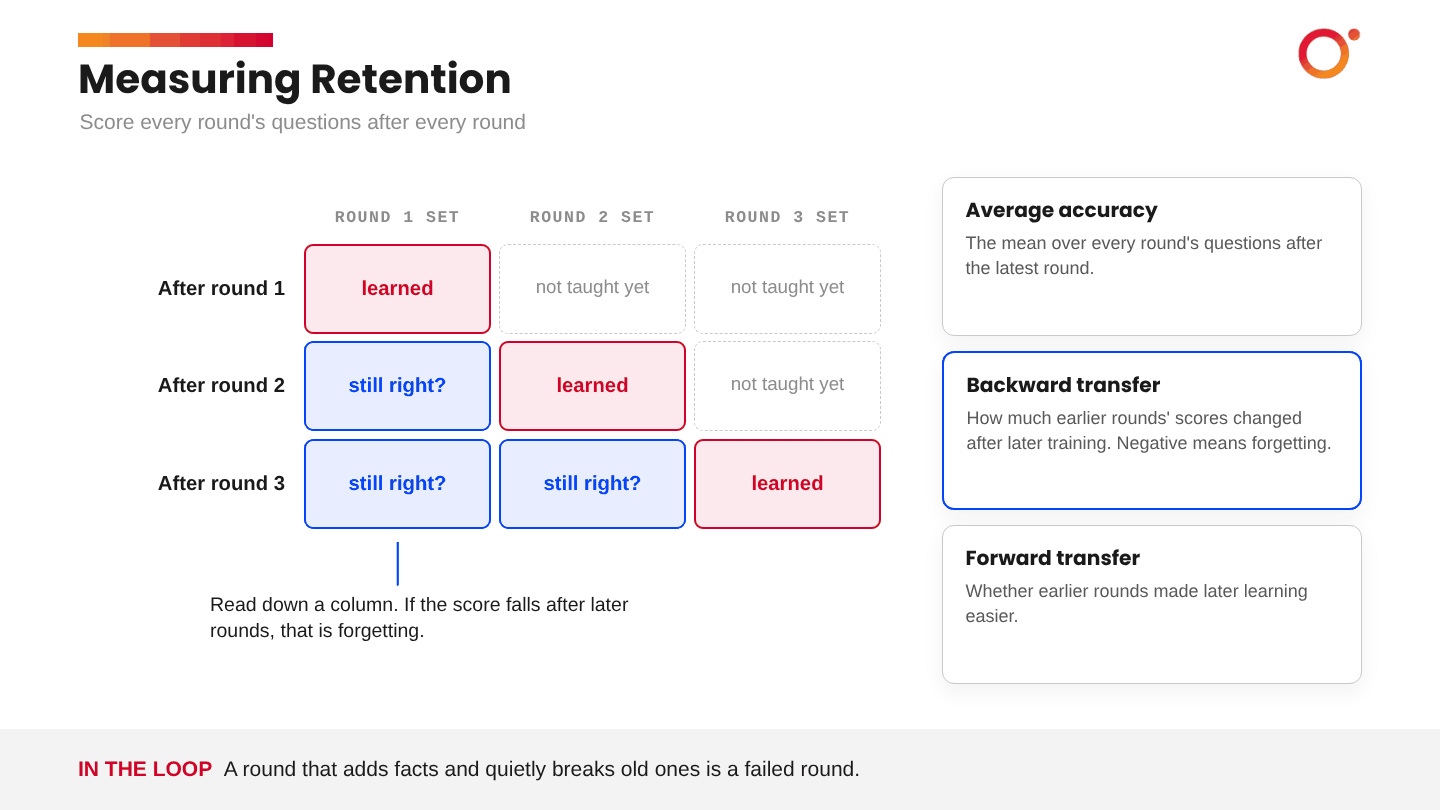

*Figure 13. The retention grid. Each row is a moment in time, each column is one round's questions. A round that adds facts and quietly breaks old ones is a failed round.*

Rows are "after training round *k*". Columns are "round *j*'s questions". The cell on the diagonal is how well a round was learned when it was fresh. Read **down a column** to see what later training did to that round's knowledge.

## The three numbers

**Average accuracy (ACC)** is the score across every valid question from every round, after the final round. In this notebook it is weighted by question, so round 1's larger set counts for more.

**Backward transfer (BWT)** measures what later training did to earlier rounds. For each earlier round $j$, take its score after the final round $K$ and subtract its score right after it was learned, then average:

$$\text{BWT} = \frac{1}{K-1} \sum_{j=1}^{K-1} \left( R_{K,j} - R_{j,j} \right)$$

$R_{k,j}$ is the score on round $j$'s questions after training round $k$. A negative BWT is forgetting. Zero means earlier rounds held. A positive value means later training helped earlier questions, which can happen when rounds are related. Both metrics come from the paper *Gradient Episodic Memory for Continual Learning*.

**Changed-fact accuracy** is the number of changed-fact questions that pass after the final round: new value present, old value absent.

One detail keeps BWT fair. A round-1 question that is retired when its fact changes is not counted as forgotten. Both sides of the subtraction use only the questions still valid at the end.

## A worked example

The next cell computes ACC and BWT by hand on a made-up grid, so the formula is concrete before the real numbers arrive. For simplicity it averages the columns directly.

In [ ]:
toy = pd.DataFrame(
    {"round 1 Qs": [85, 70, 60], "round 2 Qs": [None, 90, 80], "round 3 Qs": [None, None, 88]},
    index = ["after round 1", "after round 2", "after round 3"],
)
print(toy.to_string(na_rep = ""))

acc = toy.loc["after round 3"].mean()
round1_change = toy.loc["after round 3", "round 1 Qs"] - toy.loc["after round 1", "round 1 Qs"]
round2_change = toy.loc["after round 3", "round 2 Qs"] - toy.loc["after round 2", "round 2 Qs"]
print(f"\nACC after round 3: ({' + '.join(str(int(v)) for v in toy.loc['after round 3'])}) / 3 = {acc:.1f}")
print(f"Round 1 changed by {round1_change:+.0f} points, round 2 by {round2_change:+.0f} points")
print(f"BWT = ({round1_change:+.0f} {round2_change:+.0f}) / 2 = {(round1_change + round2_change) / 2:+.1f}")

In that example the model ends with a respectable average of 76, and a BWT of about -18 says it got there by losing a good part of what it knew. ACC alone would have hidden that.

## Your grid

`grid(arm)` lays the stored results out as the table described above. `metrics(arm)` computes the three numbers, plus the `prior_knowledge` score: five questions about public insurance terms and general ability, which should not move at all.

In [ ]:
def grid(arm):
    g = pd.DataFrame(index = [f"after round {k}" for k in ROUNDS], columns = [f"round {j} Qs" for j in ROUNDS], dtype = object)
    for k, df in RESULTS[arm].items():
        if k == 0: continue
        for j, sub in df.groupby("round"):
            g.loc[f"after round {k}", f"round {j} Qs"] = f"{sub.passed.mean()*100:.0f}%  ({sub.passed.sum()}/{len(sub)})"
    return g.fillna("")


def metrics(arm):
    K = max(k for k in RESULTS[arm] if k > 0)
    final = RESULTS[arm][K]
    acc = final.passed.mean() * 100
    bwt_parts = []
    for j in ROUNDS:
        if j >= K: continue
        valid_ids = set(final[final["round"] == j]["id"])          # still valid at the end
        then = RESULTS[arm][j]; then = then[(then["round"] == j) & then["id"].isin(valid_ids)]
        now  = final[(final["round"] == j)]
        bwt_parts.append(now.passed.mean() * 100 - then.passed.mean() * 100)
    bwt = sum(bwt_parts) / len(bwt_parts) if bwt_parts else float("nan")
    changed = final[final["category"] == "changed_fact"]
    return {"arm": arm, "ACC (final, all rounds)": round(acc, 1), "BWT (mean, earlier rounds)": round(bwt, 1),
            "changed facts correct": f"{changed.passed.sum()}/{len(changed)}",
            "prior knowledge": f"{final[final.category == 'prior_knowledge'].passed.sum()}/{(final.category == 'prior_knowledge').sum()}"}


for arm in ("naive", "replay"):
    print(f"\n===== {arm.upper()} =====")
    print(grid(arm).to_string())
print("\n")
print(pd.DataFrame([metrics("naive"), metrics("replay")]).set_index("arm").T.to_string())

The same grid as a picture: one panel for round 1's questions and one for round 2's, with a line per arm. A line that slopes down is forgetting. The gap between the two lines is what replay bought.

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize = (10, 3.5), sharey = True)
for ax, j in zip(axes, (1, 2)):
    for arm, colour in (("naive", "#8C8C8C"), ("replay", "#D3002D")):
        ks = [k for k in ROUNDS if k >= j and k in RESULTS.get(arm, {})]
        ys = [RESULTS[arm][k][RESULTS[arm][k]["round"] == j].passed.mean() * 100 for k in ks]
        ax.plot(ks, ys, marker = "o", color = colour, linewidth = 2, label = arm)
    ax.set_title(f"Round {j}'s questions")
    ax.set_xlabel("after training round")
    ax.set_xticks(ROUNDS)
axes[0].set_ylabel("held-out score (%)")
axes[0].legend()
plt.tight_layout()
plt.show()

---
# Part 12: The changed facts, and what each round lost

Summary numbers say how much changed. The next two cells show **which answers** changed, and that is where the understanding comes from.

## The changed facts, round by round

For each of the five changed facts, the next cell prints the old and new key terms, the question, and what the model answered after every round in both arms. Before the change, it shows the result for the round-1 version of the question, which expects the old value. From the change onward, it shows the new version. The wording of the question is identical in both; only the expected answer differs.

Look for two things:

- **Did the new value arrive?** In the round where the fact changes, does the answer switch to the new value?
- **Does the old value come back?** A fact that changed in round 2 is tested again after round 3. Round 3 does not train on it in the naive arm, so check whether the answer holds.

In [ ]:
changed_items = [(r, it) for r in (2, 3) for it in eval_items[r] if it.get("supersedes")]
for r_changed, it in changed_items:
    old = next(i for i in eval_items[1] if i.get("fact_id") == it["supersedes"])
    print(f"\n### {it['supersedes']} -> {it['fact_id']}  (changed in round {r_changed})")
    print("   old key terms:", old["must_include"], "  new key terms:", it["must_include"])
    print("   Q:", it["question"])
    for arm in ("naive", "replay"):
        for k in ROUNDS:
            df = RESULTS[arm][k]
            row = df[df["id"] == (it["id"] if k >= r_changed else old["id"])]
            if len(row):
                a = row.iloc[0]
                print(f"   [{arm:6s} after r{k}] {'PASS' if a.passed else 'FAIL'}: {a.answer[:150].replace(chr(10), ' ')}")

## What each round lost and recovered

The next cell compares consecutive rounds within each arm. On earlier rounds' questions, it counts the answers that flipped from pass to fail (**lost**) and from fail to pass (**recovered**), and prints up to five of the lost ones with the answer before and after.

Read the lost answers for a pattern. Are they concentrated in one category, such as status codes or numeric limits? Do they come from topics that the later round also touched (a new Q-code blurring the old ones), or from unrelated topics?

In [ ]:
for arm in ("naive", "replay"):
    print(f"\n===== {arm.upper()} =====")
    for k in ROUNDS[1:]:
        prev, cur = RESULTS[arm][k-1], RESULTS[arm][k]
        m = prev.merge(cur, on = ["id", "round", "category", "question"], suffixes = ("_prev", "_cur"))
        m = m[m["round"] < k]
        lost, gained = m[m.passed_prev & ~m.passed_cur], m[~m.passed_prev & m.passed_cur]
        print(f"after round {k}: lost {len(lost)}, recovered {len(gained)} on earlier rounds' questions")
        for _, x in lost.head(5).iterrows():
            print(f"   LOST  [r{x['round']} {x.category}] {x.question[:80]}")
            print(f"         was: {x.answer_prev[:100].replace(chr(10), ' ')}")
            print(f"         now: {x.answer_cur[:100].replace(chr(10), ' ')}")

---
# Part 13: Reading the results and where to go next

## How to read your results

- **Arm A's round-1 column is the forgetting curve.** If it falls by twenty points over two rounds, that is catastrophic forgetting on a small scale. If it barely moves, the short later rounds and LoRA's limited capacity are doing the protecting.
- **Arm B's round-1 column should fall less, or not at all.** The difference between the two columns is the value of replay in this setting.
- **Changed facts are the hardest test.** A pass needs the new value present and the old one absent. Replay helps here only because the pool excludes superseded rows. Replay without that filter would make these worse.
- **A later round may score slightly higher in Arm A than in Arm B.** In Arm A all of the round's gradient went to the new facts. That is the trade-off between learning and forgetting, made visible.
- **Prior knowledge should not move.** If it drops in either arm, training is leaking past the Calderwood context.
- **Mind the small numbers.** Round 3 has 14 questions, so one answer is seven points. There are five changed facts, so one answer is twenty. Treat a single run as an observation, and rerun with another seed before drawing a firm conclusion.

## What to try next

1. **Replay fraction:** 0.1, 0.2, 0.5. More replay means less forgetting and longer rounds.
2. **A lower learning rate for rounds 2 and 3** (1e-4). Later rounds have fewer rows and may need smaller steps.
3. **One adapter per round**, kept separately, against the single evolving adapter used here. Separate adapters never forget, but something has to choose which one answers.
4. **A regularisation method:** elastic weight consolidation, or a penalty on answers that drift from the previous round's model.
5. **Replay without the filter.** Remove the superseded-row check in `make_rows` and watch the changed facts. It is a quick way to see why the filter exists.
6. **Real traces** from an agent's memory store in place of the simulated ones. The pipeline stays the same; only the first stage changes.

## Save the run

The next cell gathers everything into one place.

| Output | What it holds |
|---|---|
| `results/all_results.jsonl` | Every answer from every evaluation in both arms |
| `results/metrics.json` | The settings used, and the summary metrics for each arm |
| `calderwood_cl_results.zip` | The `results/` folder zipped, ready to download |
| `adapters/` | One saved adapter per arm and round, written during training |

In [ ]:
# Save everything from this run in one place
import shutil
os.makedirs("results", exist_ok = True)
all_df = pd.concat([df for arm in RESULTS for df in RESULTS[arm].values()], ignore_index = True)
all_df.to_json("results/all_results.jsonl", orient = "records", lines = True, force_ascii = False)
json.dump({"settings": {"QUICK": QUICK, "EPOCHS": EPOCHS, "REPLAY_FRACTION": REPLAY_FRACTION, "LEARNING_RATE": LEARNING_RATE},
           "metrics": [metrics("naive"), metrics("replay")]}, open("results/metrics.json", "w"), indent = 2)
shutil.make_archive("calderwood_cl_results", "zip", "results")
print("results/all_results.jsonl, results/metrics.json and calderwood_cl_results.zip written; adapters are under adapters/")

## Beyond this notebook: a loop in production

Three decisions sit around the loop you have just run.

**What crosses into the weights.** Not every memory unit belongs there. Good signals that one does: it is recalled often, it has been stable for several rounds, and retrieval misses it. Knowledge that changes often, must be cited, or is personal to one customer should stay in the store, where one edit fixes it.

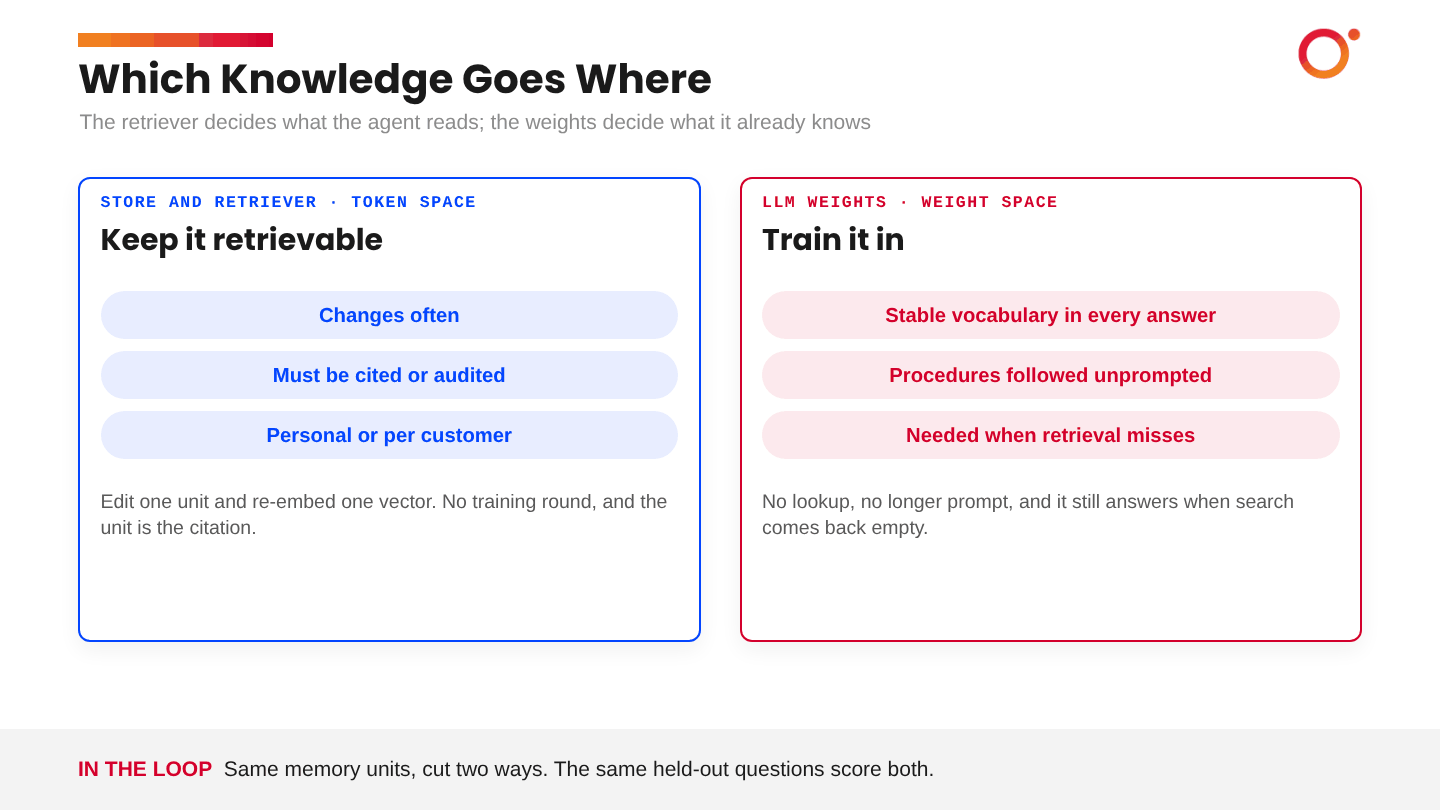

*Figure 14. The same memory units, cut two ways. The store handles what changes and what must be cited; the weights hold the stable core.*

**How often each part retrains.** An agent with memory has two things that can be fine-tuned: the LLM, and the embedding model that retrieves memories. They do not need the same schedule. A new fact is searchable the moment it is written and embedded, with no training at all. It reaches the weights only at the next training round.

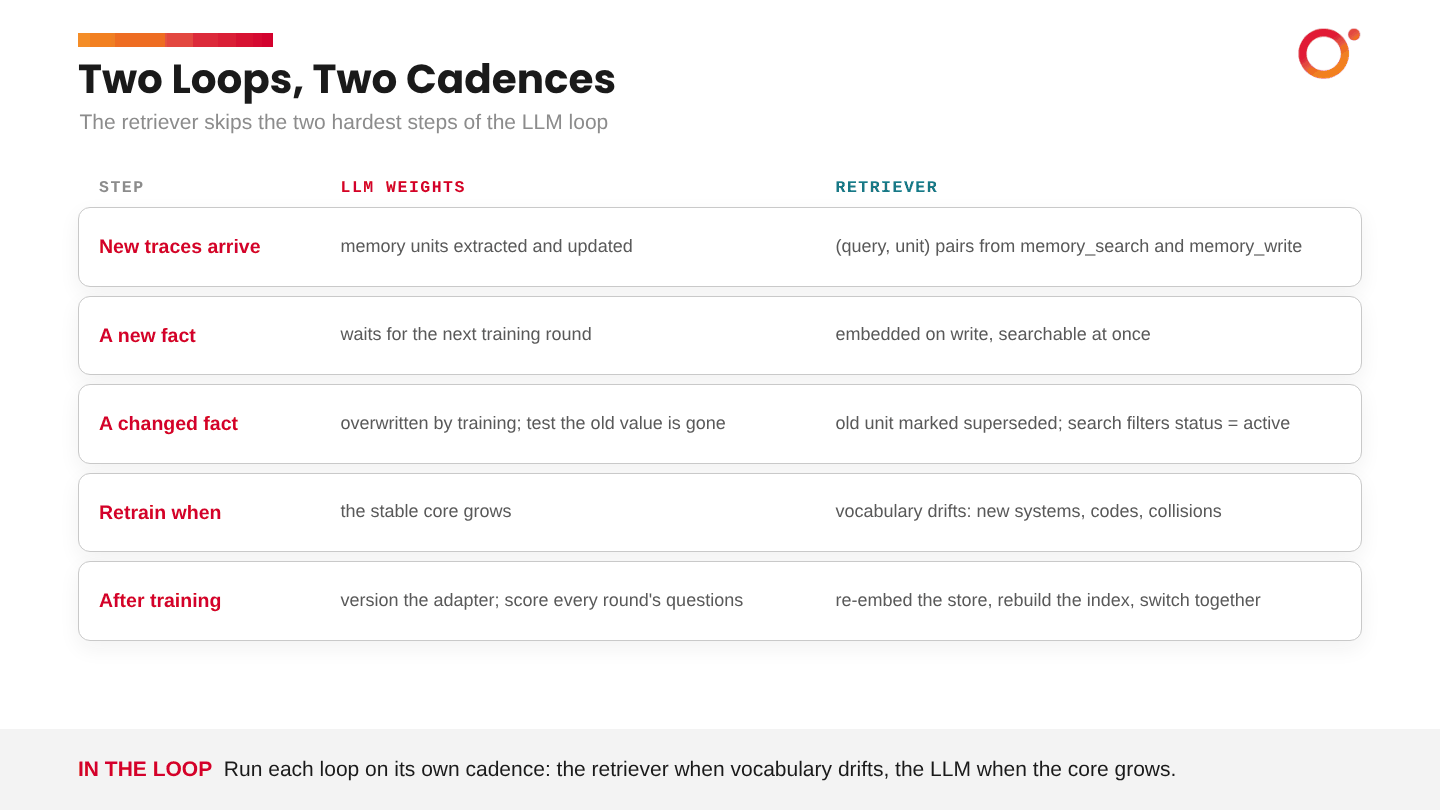

*Figure 15. Two loops on two cadences. The store absorbs new and changed facts immediately; the weights catch up when the stable core has grown enough to justify a round.*

**When a round is allowed to ship.** The retention grid is the gate. A round that adds facts and breaks old ones should not replace the adapter in production. Version every adapter with the traces and units it was built from, its settings and its scores, so that a bad round can be rolled back to the one before.

That policy, deciding what crosses from the store into the model, when, and on what evidence, is where memory engineering and model training meet.

---
# Reference

## Common errors and what they mean

| Symptom | Likely cause | Fix |
|---|---|---|
| "Missing rounds/round1_traces.jsonl" assertion | The first-run zip was uploaded, or the zip went into `sample_data` | Upload `calderwood_data_v2.zip` to the root folder and rerun the cell |
| "Please install bitsandbytes" when loading the model | The install cell skipped a package without saying so | Run the install check cell in Part 4, then restart the session and rerun from the settings cell |
| CUDA out of memory while loading | The card is smaller than 80GB | Run the GPU check in Part 6 and set `load_in_4bit = True` (or `load_in_8bit = True` on a 40GB card) |
| CUDA out of memory during training | Activations from batch size × sequence length | In `train_round`, use `per_device_train_batch_size = 2` and `gradient_accumulation_steps = 4`: the same effective batch |
| Arm B's round-1 score differs from Arm A's | The reset cell was skipped, so Arm B started from Arm A's adapter | Rerun the Arm B cell from the top; `reset_adapters()` must print its confirmation first |
| `KeyError` in `metrics` or `grid` | An arm has not finished all three rounds | Finish both arm cells before Part 11 |
| "changed facts correct" shows `0/0` | `QUICK = True` and no changed-fact question fell in the subset | Run with `QUICK = False` for the changed-fact numbers |
| The session disconnected partway through | Colab timed out | Each evaluation is already saved under `results/`, and each round's adapter under `adapters/`. Reload them, or rerun the arm that was interrupted |
| A changed fact fails with what looks like a correct answer | The answer mentions the old value while explaining the change | Read the answer in Part 12; this is the scorer's known false negative |
| Scores swing between runs | Sampling left on, or a changed system prompt | Keep `do_sample = False` and the same prompt throughout |

## Glossary

| Term | Meaning |
|---|---|
| Adapter | The small set of trained LoRA weights, saved separately from the base model |
| Arm | One version of an experiment; here, naive or replay |
| Average accuracy (ACC) | The score across all rounds' questions after the final round |
| Backward transfer (BWT) | The change in earlier rounds' scores after later training; negative means forgetting |
| Catastrophic forgetting | Loss of existing ability caused by training on new data |
| Changed fact | A fact whose value is replaced in a later round |
| Complementary learning systems | The theory that the brain pairs a fast episodic store with a slow general learner |
| Consolidation | Moving selected knowledge from an external store into the weights |
| Continual learning | Accumulating information and experience repeatedly, over time, keeping what came before |
| Elastic weight consolidation | A regulariser that slows learning on weights that mattered for earlier tasks |
| Epoch | One full pass over a round's training rows |
| Forward transfer | Whether earlier rounds made later rounds easier to learn |
| Greedy decoding | Always choosing the most likely next token |
| Held-out set | Evaluation questions kept out of training and out of the traces |
| Interference | New learning damaging old knowledge that shares the same weights |
| LoRA | Low-Rank Adaptation: a trained low-rank update beside frozen weights |
| Memory unit | One self-contained piece of knowledge extracted from traces |
| `must_exclude` | Key terms that must not appear in an answer; the old value of a changed fact |
| Naive sequential training | Training each round only on its own data |
| Refine cycle | An offline pass that reorganises the memory store: merging, deduplicating, promoting |
| Replay | Mixing earlier rows into a later round's training set |
| Replay pool | The earlier rows eligible for replay, with superseded rows removed |
| Retention grid | Scores for every round's questions after every round of training |
| Retired question | A held-out question dropped once its fact has changed |
| Round | One pass of the loop: new traces, new units, training, evaluation |
| Step | One weight update |
| Superseded | The status of a memory unit that a newer unit has replaced; kept, not deleted |
| Token space | Text outside the model that it reads: the store and the context window |
| Weight space | The model's parameters and any adapters trained on them |

## Further reading

- *Catastrophic Interference in Connectionist Networks*, McCloskey and Cohen, 1989. The origin of the forgetting problem.
- *Why There Are Complementary Learning Systems in the Hippocampus and Neocortex*, McClelland, McNaughton and O'Reilly, 1995. Two systems and replay.
- *Overcoming Catastrophic Forgetting in Neural Networks*, Kirkpatrick et al., 2017. Elastic weight consolidation.
- *Gradient Episodic Memory for Continual Learning*, Lopez-Paz and Ranzato, 2017. Average accuracy, backward and forward transfer.
- *Learning without Forgetting*, Li and Hoiem, 2016. Keeping the new model's answers close to the old model's.
- *LoRA: Low-Rank Adaptation of Large Language Models*, Hu et al., 2021.
- *LoRA Learns Less and Forgets Less*, Biderman et al., 2024. The trade-off against full fine-tuning.
- *Does Fine-Tuning LLMs on New Knowledge Encourage Hallucinations?*, Gekhman et al., 2024.
- The first notebook in this pair, `Qwen3_5_27B_Calderwood_memory_traces_guided.ipynb`, for weights, LoRA and the training settings from the ground up.